# Colorectal adenoma-carcinoma progression
Hiu Mai

I wanted to understand which molecular changes are already present in colorectal adenomas and persist in early carcinoma, and whether those changes could help identify polyphenols for further study. Adenomas provide an opportunity to investigate prevention before invasive cancer develops. This question led me from tissue expression profiles to protein networks, compound prioritization and structural assessment.

This notebook follows the analysis from the expression matrix to the compound ranking and docking scores. It accompanies my [submitted manuscript](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/manuscript/submitted-manuscript.pdf). The [repository](https://github.com/hiuuuuu33/colorectal-polyphenol-research) contains the inputs, original research files and source records.

[Research abstract](#research-abstract) · [Expression analysis](#expression-analysis) · [Progression-associated genes](#progression-genes) · [Functional enrichment](#functional-enrichment) · [Protein network](#protein-network) · [Polyphenol prioritization](#polyphenol-prioritization) · [Docking and structure selection](#docking) · [Checks and references](#checks-and-references)

<a id="research-abstract"></a>
## Research abstract
Adapted from the abstract and results of my submitted manuscript.

I investigated transcriptional changes across normal colorectal tissue, adenoma and early colorectal cancer (CRC), then used those changes to prioritize bioactive polyphenols. I analyzed [GSE228012](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE228012): adenomas from 11 individuals and paired stage-I CRC and adjacent normal tissues from another 11 patients. Differential expression identified 725 genes in adenoma versus normal tissue, 312 in CRC versus adenoma, and 1,544 in CRC versus normal tissue. Twenty-nine genes changed concordantly across both sequential comparisons: eight increased and 21 decreased.

Functional enrichment linked adenoma formation to inflammatory recruitment and loss of differentiated epithelial and metabolic functions. Carcinoma showed additional extracellular-matrix organization, focal adhesion and cell-cycle activity. The 29 progression-associated proteins formed a STRING network with 61 associations. I then used the human interactome to connect disease-associated proteins with recorded compound targets. Of 66 compound entries representing 65 unique chemical identities, 11 identities met the network-proximity cutoff. Kaempferol ranked first, followed by 4-methylcatechol, quercetin, punicalagin and umbelliferone.

I assessed the ten highest-ranked compounds against two progression-associated proteins with experimentally resolved structures, CXCL8 and ADH1C. Phloretin had the most favorable Vina score in the 6WZM receptor system (-6.1 kcal/mol), and kaempferol led the 1HT0 system (-8.3 kcal/mol). Together, the expression, network and structural results identify kaempferol as a leading candidate for experimental follow-up and provide a framework for investigating compounds relevant to adenoma-carcinoma progression.

### How the analyses connect
The expression comparisons define changes associated with the tissue stages. I use the genes that change in the same direction across both sequential comparisons as the focused progression-associated set. Enrichment places the broader expression changes in biological pathways; the protein network shows relationships within the 29-gene set. Network proximity then ranks compounds by the positions of their targets in the human interactome. Docking adds a structural assessment of selected proteins using experimental atomic coordinates. Each section below follows one of these questions through its code and results.

## Setup
I load the plotting packages and the functions used to read the archived results. The expression model and plotting steps are written out below. All data paths are relative to the repository folder.

In [1]:
root <- normalizePath(Sys.getenv("RESEARCH_REPO_ROOT", unset = getwd()), mustWork = TRUE)
stopifnot(file.exists(file.path(root, "data", "transcriptomics")))
setwd(root)
python <- Sys.getenv("PYTHON", unset = Sys.which("python3"))
if (!nzchar(python)) stop("Python 3 is required; set PYTHON to its executable.")
library(limma)
library(ggplot2)
library(ggrepel)
library(patchwork)
source("scripts/R/01_transcriptomics.R")
source("scripts/R/02_enrichment_figures.R")
source("scripts/R/04_docking.R")
options(repr.plot.width = 12, repr.plot.height = 9, repr.plot.res = 150,
        jupyter.plot_mimetypes = "image/png", warn = 1)
set.seed(20261104)
show_table <- function(data, caption = NULL, digits = 3) {
  IRdisplay::display_html(as.character(knitr::kable(data, format = "html", row.names = FALSE,
                                                   caption = caption, digits = digits)))
}
stage_colors <- c(Normal = "#00A087", Adenoma = "#E64B35", CRC = "#3C5488")
plot_theme <- theme_bw(base_size = 12) +
  theme(plot.title = element_text(face = "bold"), legend.title = element_blank())

<a id="expression-analysis"></a>
## Expression analysis
GSE228012 contains 33 samples, with 11 samples in each tissue group. The adenomas come from 11 individuals; cancer and adjacent normal tissue are paired samples from a separate group of 11 patients. These are cross-sectional comparisons of tissue stages. I begin with the processed FPKM matrix. For repeated gene symbols, I retain the row with the highest mean expression, then recover the tissue labels from the sample names.

In [2]:
raw <- read.delim("data/transcriptomics/GSE228012_all.gene.FPKM.mRNA_processed.txt",
                  check.names = TRUE)
symbols <- as.character(raw[[2]])
fpkm <- as.matrix(raw[, -(1:2)])
storage.mode(fpkm) <- "double"
ranked <- order(rowMeans(fpkm), decreasing = TRUE)
retained <- ranked[!duplicated(symbols[ranked])]
fpkm <- fpkm[retained, , drop = FALSE]
rownames(fpkm) <- symbols[retained]
colnames(fpkm) <- trimws(sub("\\.FPKM$", "", colnames(fpkm)))
group <- ifelse(grepl("T$", colnames(fpkm)), "CRC",
                 ifelse(grepl("N$", colnames(fpkm)), "Normal",
                        ifelse(grepl("pre$", colnames(fpkm)), "Adenoma", NA_character_)))
stopifnot(!anyNA(group))
group <- factor(group, levels = c("Normal", "Adenoma", "CRC"))
sample_info <- data.frame(sample = colnames(fpkm), group = group)
show_table(as.data.frame(table(group)), "Samples in each tissue group")

group,Freq
Normal,11
Adenoma,11
CRC,11


I keep genes with FPKM > 1 in at least seven samples, using the original filter `round(0.2 * 33)`. I then apply log2(FPKM + 1). This leaves 12,298 genes for the expression comparisons.

In [3]:
keep <- rowSums(fpkm > 1) >= round(0.2 * ncol(fpkm))
log2_fpkm <- log2(fpkm[keep, , drop = FALSE] + 1)
preprocessing <- data.frame(
  step = c("Input rows", "Unique gene symbols", "Genes after filtering", "Samples"),
  value = c(nrow(raw), nrow(fpkm), nrow(log2_fpkm), ncol(log2_fpkm))
)
show_table(preprocessing, "Expression preprocessing")

step,value
Input rows,18116
Unique gene symbols,18114
Genes after filtering,12298
Samples,33


### Differential expression
I fit the original three-group limma model and compare adenoma with normal tissue, carcinoma with adenoma, and carcinoma with normal tissue. I use Benjamini-Hochberg adjusted P < 0.05 and absolute log2 fold change > 1 to select differentially expressed genes.

In [4]:
design <- model.matrix(~0 + group)
colnames(design) <- levels(group)
contrasts <- makeContrasts(
  Adenoma_vs_Normal = Adenoma - Normal,
  CRC_vs_Adenoma = CRC - Adenoma,
  CRC_vs_Normal = CRC - Normal, levels = design
)
fit <- eBayes(contrasts.fit(lmFit(log2_fpkm, design), contrasts))
de <- lapply(colnames(contrasts), function(contrast) {
  dat <- topTable(fit, coef = contrast, number = Inf, adjust.method = "BH")
  dat$gene <- rownames(dat)
  dat <- dat[, c("gene", setdiff(names(dat), "gene"))]
  dat$direction <- ifelse(dat$adj.P.Val < 0.05 & dat$logFC > 1, "Up",
                          ifelse(dat$adj.P.Val < 0.05 & dat$logFC < -1, "Down", "Stable"))
  dat
})
names(de) <- colnames(contrasts)
de_summary <- do.call(rbind, lapply(names(de), function(contrast) {
  dat <- de[[contrast]]
  data.frame(contrast = contrast, tested = nrow(dat),
             significant = sum(dat$direction != "Stable"),
             up = sum(dat$direction == "Up"), down = sum(dat$direction == "Down"))
}))
show_table(de_summary, "Differential-expression results")

contrast,tested,significant,up,down
Adenoma_vs_Normal,12298,725,254,471
CRC_vs_Adenoma,12298,312,178,134
CRC_vs_Normal,12298,1544,855,689


### PCA and volcano plots
I use PCA to examine variation across the samples. Each gene is centered and scaled to unit variance, following the original analysis. The first two components account for 25.6% and 11.6% of the variance.

In [5]:
pca <- prcomp(t(log2_fpkm), center = TRUE, scale. = TRUE)
variance <- 100 * pca$sdev^2 / sum(pca$sdev^2)
pc <- data.frame(PC1 = pca$x[, 1], PC2 = pca$x[, 2], group = group)
pca_plot <- ggplot(pc, aes(PC1, PC2, color = group, shape = group)) +
  stat_ellipse(type = "norm", linewidth = 0.5, show.legend = FALSE) +
  geom_point(size = 3) + scale_color_manual(values = stage_colors) +
  labs(title = "PCA of GSE228012",
       x = sprintf("PC1 (%.1f%%)", variance[1]),
       y = sprintf("PC2 (%.1f%%)", variance[2])) + plot_theme
show_table(data.frame(component = c("PC1", "PC2"), variance_percent = variance[1:2]),
           "Variance explained by the first two components", digits = 1)

component,variance_percent
PC1,25.6
PC2,11.6


The volcano plots place the size of each expression change against its adjusted P value. I combine them with the PCA plot to reproduce Figure 1. The comparisons yield 725 significant genes in adenoma versus normal tissue, 312 in carcinoma versus adenoma, and 1,544 in carcinoma versus normal tissue. More genes pass the threshold in the first sequential comparison than in the second, directing attention to molecular changes already present at the adenoma stage.

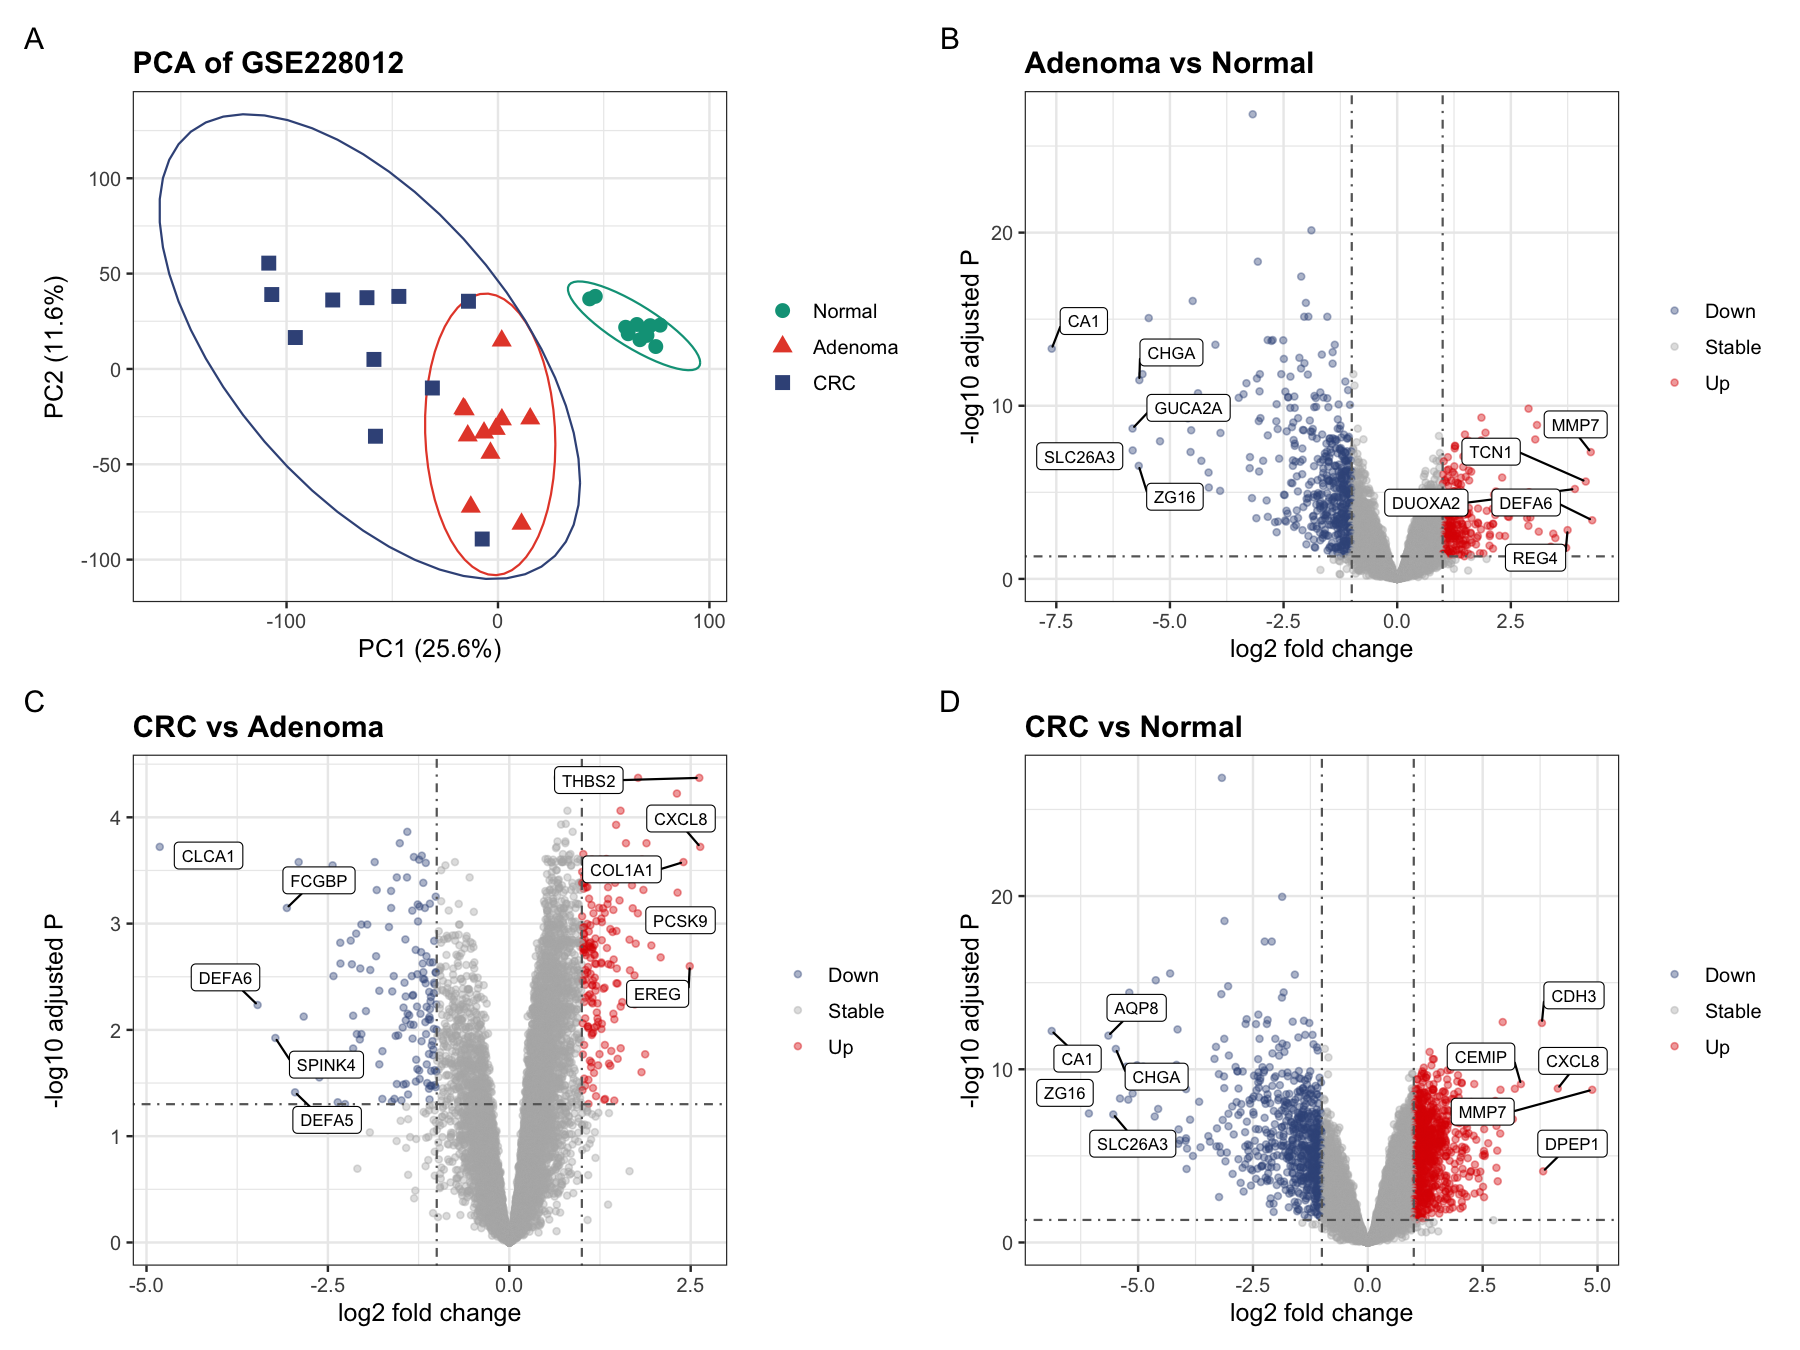

In [6]:
options(repr.plot.width = 12, repr.plot.height = 9)
volcano_plots <- lapply(names(de), function(contrast) {
  dat <- de[[contrast]]
  dat$neg_log10_adjP <- -log10(pmax(dat$adj.P.Val, .Machine$double.xmin))
  upper <- dat[dat$direction == "Up", ]
  lower <- dat[dat$direction == "Down", ]
  labels <- rbind(head(upper[order(-upper$logFC), ], 5),
                  head(lower[order(lower$logFC), ], 5))
  ggplot(dat, aes(logFC, neg_log10_adjP)) +
    geom_point(aes(color = direction), alpha = 0.4, size = 1.2) +
    scale_color_manual(values = c(Up = "#DC0000", Down = "#3C5488", Stable = "grey70")) +
    geom_vline(xintercept = c(-1, 1), linetype = 4, color = "grey40", linewidth = 0.5) +
    geom_hline(yintercept = -log10(0.05), linetype = 4, color = "grey40", linewidth = 0.5) +
    geom_label_repel(data = labels, aes(label = gene), seed = 20261104,
                     color = "black", size = 2.8, max.overlaps = Inf, box.padding = 0.4) +
    labs(title = gsub("_", " ", contrast),
         x = "log2 fold change", y = "-log10 adjusted P") + plot_theme
})
figure1 <- wrap_plots(c(list(pca_plot), volcano_plots), ncol = 2) +
  plot_annotation(tag_levels = "A")
figure1

<a id="progression-genes"></a>
## Progression-associated genes
I next look for genes that change in the same direction across both sequential comparisons. I intersect the upregulated genes in adenoma versus normal and carcinoma versus adenoma, and repeat this for the downregulated genes. The result contains eight up/up genes and 21 down/down genes. This focuses the next analysis on changes shared by both transitions, rather than selecting genes from the cancer-normal contrast alone.

In [7]:
na <- de$Adenoma_vs_Normal
ac <- de$CRC_vs_Adenoma
nc <- de$CRC_vs_Normal
up <- intersect(na$gene[na$direction == "Up"], ac$gene[ac$direction == "Up"])
down <- intersect(na$gene[na$direction == "Down"], ac$gene[ac$direction == "Down"])
build_progressive <- function(genes, direction) {
  data.frame(gene = genes,
             logFC_NA = na$logFC[match(genes, na$gene)],
             adjP_NA = na$adj.P.Val[match(genes, na$gene)],
             logFC_AC = ac$logFC[match(genes, ac$gene)],
             adjP_AC = ac$adj.P.Val[match(genes, ac$gene)],
             logFC_NC = nc$logFC[match(genes, nc$gene)],
             adjP_NC = nc$adj.P.Val[match(genes, nc$gene)], direction = direction)
}
prog <- rbind(build_progressive(up, "Up-Up"), build_progressive(down, "Down-Down"))
show_table(prog[, c("gene", "direction", "logFC_NA", "logFC_AC", "logFC_NC")],
           "The 29 progression-associated genes")

gene,direction,logFC_NA,logFC_AC,logFC_NC
TNFRSF12A,Up-Up,1.424,1.608,3.033
HIST3H2A,Up-Up,1.134,1.119,2.253
SLCO4A1,Up-Up,1.168,1.033,2.201
MYC,Up-Up,1.108,1.195,2.303
COL12A1,Up-Up,1.328,1.033,2.361
CXCL8,Up-Up,1.503,2.632,4.135
SLC22A3,Up-Up,1.091,1.032,2.123
CXCL2,Up-Up,1.139,1.405,2.545
CHP2,Down-Down,-3.239,-1.107,-4.346
TNFRSF17,Down-Down,-1.694,-1.059,-2.753


### Heatmap and expression trajectories
For the heatmap, I standardize each gene across samples so that genes with different expression levels can be compared. The columns follow the normal-adenoma-carcinoma order; the rows are clustered.

In [8]:
stage_order <- order(group)
heat <- log2_fpkm[prog$gene, stage_order, drop = FALSE]
heat_z <- t(scale(t(heat)))
col_anno <- data.frame(Stage = group[stage_order], row.names = colnames(heat))
row_anno <- data.frame(Direction = prog$direction, row.names = prog$gene)
heatmap <- pheatmap::pheatmap(
  heat_z, silent = TRUE, cluster_cols = FALSE, cluster_rows = TRUE,
  show_colnames = FALSE, fontsize_row = 8, annotation_col = col_anno,
  annotation_row = row_anno,
  annotation_colors = list(Stage = stage_colors,
                            Direction = c("Up-Up" = "#DC0000", "Down-Down" = "#3C5488")),
  gaps_col = c(11, 22), main = "29 progression-associated genes"
)

I calculate the mean log-transformed expression in each tissue group to draw the trajectories. The first eight rows below show the values used for the up/up genes.

In [9]:
means <- data.frame(
  gene = prog$gene, direction = prog$direction,
  Normal = rowMeans(log2_fpkm[prog$gene, group == "Normal", drop = FALSE]),
  Adenoma = rowMeans(log2_fpkm[prog$gene, group == "Adenoma", drop = FALSE]),
  CRC = rowMeans(log2_fpkm[prog$gene, group == "CRC", drop = FALSE])
)
long <- reshape(means, varying = c("Normal", "Adenoma", "CRC"), v.names = "Expression",
                 timevar = "Stage", times = c("Normal", "Adenoma", "CRC"), direction = "long")
long$Stage <- factor(long$Stage, levels = levels(group))
show_table(head(means, 8), "Mean expression by tissue group")

gene,direction,Normal,Adenoma,CRC
TNFRSF12A,Up-Up,2.527,3.952,5.560
HIST3H2A,Up-Up,2.776,3.910,5.029
SLCO4A1,Up-Up,0.892,2.061,3.093
MYC,Up-Up,3.893,5.001,6.196
COL12A1,Up-Up,1.988,3.316,4.349
CXCL8,Up-Up,1.454,2.957,5.589
SLC22A3,Up-Up,0.448,1.540,2.572
CXCL2,Up-Up,2.051,3.190,4.596


Figure 2 combines the 29-gene heatmap with the trajectories. I show the 15 down/down genes with the largest overall changes and all eight up/up genes, matching the original plotting selection. Increasing genes include MYC, COL12A1, TNFRSF12A and CXCL8. Decreasing genes include ADH1C, CA12, HSD17B2, UGT1A10 and FABP2. In my manuscript, I interpret this combination as persistent inflammatory and stromal changes alongside loss of differentiated epithelial and metabolic functions.

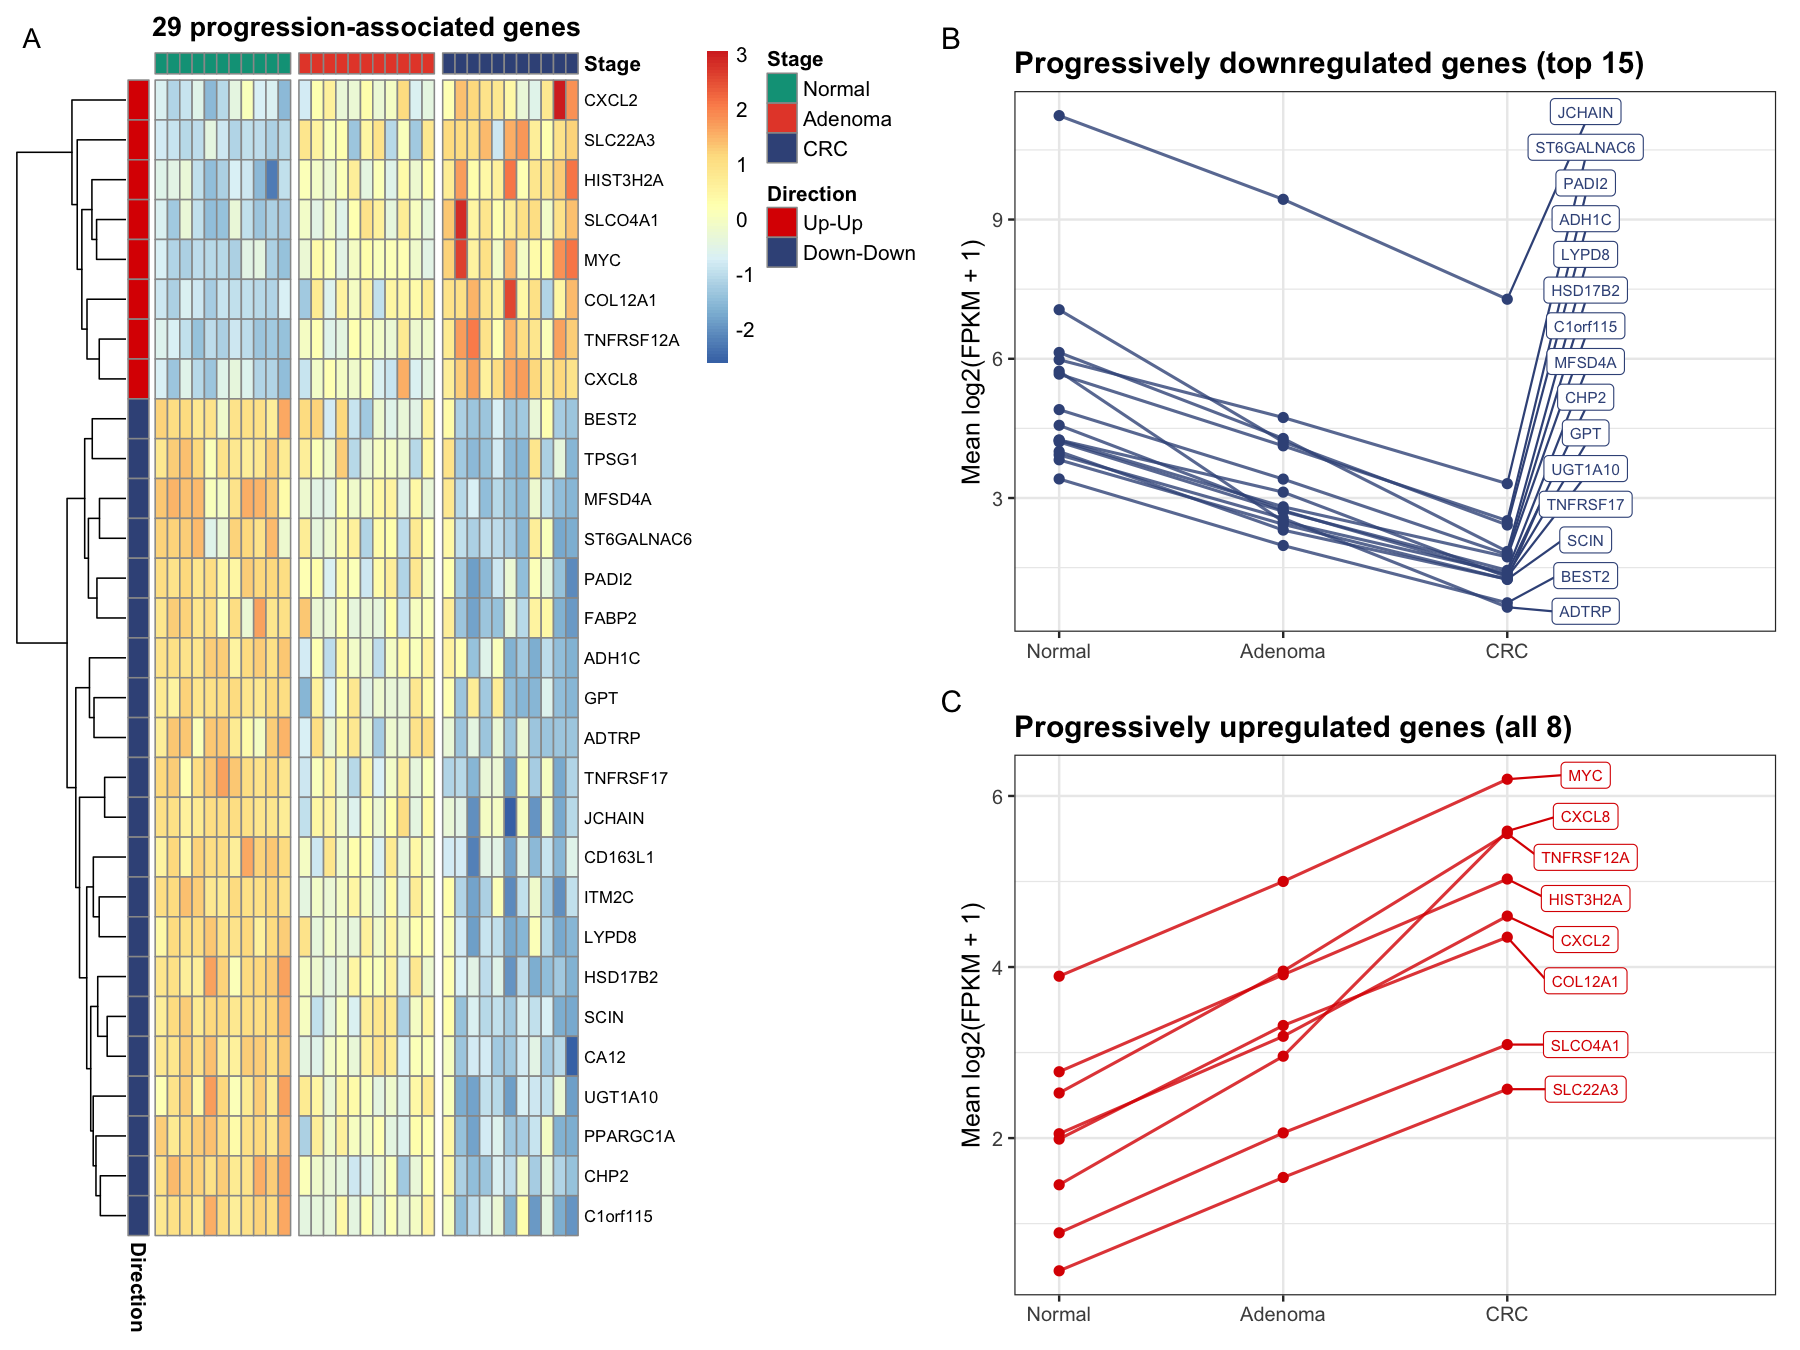

In [10]:
options(repr.plot.width = 12, repr.plot.height = 9)
line_plot <- function(direction, color, title) {
  chosen <- prog[prog$direction == direction, ]
  chosen <- head(chosen[order(-abs(chosen$logFC_NC)), "gene"], 15)
  dat <- long[long$gene %in% chosen, ]
  ggplot(dat, aes(Stage, Expression, group = gene)) +
    geom_line(color = color, linewidth = 0.7, alpha = 0.8) +
    geom_point(color = color, size = 1.8) +
    geom_label_repel(data = dat[dat$Stage == "CRC", ], aes(label = gene),
                     seed = 20261104, direction = "y", nudge_x = 0.35,
                     max.overlaps = Inf, size = 2.6, color = color) +
    scale_x_discrete(expand = expansion(add = c(0.2, 1.2))) +
    labs(title = title, x = NULL, y = "Mean log2(FPKM + 1)") + plot_theme
}
down_plot <- line_plot("Down-Down", "#3C5488", "Progressively downregulated genes (top 15)")
up_plot <- line_plot("Up-Up", "#DC0000", "Progressively upregulated genes (all 8)")
figure2 <- wrap_plots(wrap_elements(full = heatmap$gtable), down_plot, up_plot,
                      design = "AB\nAC", widths = c(1.15, 1)) +
  plot_annotation(tag_levels = "A")
figure2

<a id="functional-enrichment"></a>
## Functional enrichment
I use the complete GO and KEGG result tables saved with the project. The summary below counts the terms retained at adjusted P < 0.05 in each comparison. These are the original enrichment statistics; the following cells redraw their figures.

In [11]:
enrichment <- run_enrichment_figures(root)
show_table(enrichment$summary, "Archived enrichment results")

Enrichment figures complete: 15 frozen tables read; submitted significant-term counts verified.



contrast,category,tested_terms,significant_terms,source_mode
Adenoma_vs_Normal,GO_BP,4540,239,frozen_original_results
Adenoma_vs_Normal,GO_CC,381,21,frozen_original_results
Adenoma_vs_Normal,GO_MF,766,68,frozen_original_results
Adenoma_vs_Normal,KEGG_up,211,10,frozen_original_results
Adenoma_vs_Normal,KEGG_down,283,7,frozen_original_results
CRC_vs_Adenoma,GO_BP,3394,93,frozen_original_results
CRC_vs_Adenoma,GO_CC,322,19,frozen_original_results
CRC_vs_Adenoma,GO_MF,563,13,frozen_original_results
CRC_vs_Adenoma,KEGG_up,180,14,frozen_original_results
CRC_vs_Adenoma,KEGG_down,168,1,frozen_original_results


I plot up to 15 significant terms in each panel, ordered by gene ratio. Point size gives the gene count and color gives the adjusted P value. The same function is used for both sequential comparisons.

In [12]:
plot_enrichment <- function(contrast) {
  categories <- c("GO_BP", "GO_CC", "GO_MF", "KEGG_up", "KEGG_down")
  plots <- lapply(categories, function(category) {
    dat <- enrichment$results[[paste(contrast, category, sep = "__")]]
    significant <- dat[dat$p.adjust < 0.05, , drop = FALSE]
    shown <- head(significant[order(significant$p.adjust, significant$pvalue), ], 15)
    ratios <- strsplit(shown$GeneRatio, "/", fixed = TRUE)
    shown$GeneRatio_numeric <- vapply(ratios, function(x) as.numeric(x[1]) / as.numeric(x[2]), numeric(1))
    shown <- shown[order(shown$GeneRatio_numeric), ]
    shown$label <- vapply(shown$Description,
                          function(x) paste(strwrap(x, width = 42), collapse = "\n"), character(1))
    shown$label <- factor(shown$label, levels = unique(shown$label))
    ggplot(shown, aes(GeneRatio_numeric, label)) +
      geom_point(aes(size = Count, color = p.adjust)) +
      scale_color_gradient(low = "#CB2525", high = "#2866B0", name = "Adjusted P") +
      scale_size_continuous(range = c(3, 9), name = "Gene count") +
      labs(title = gsub("_", " ", category), subtitle = gsub("_", " ", contrast),
           x = "Gene ratio", y = NULL) +
      theme_bw(base_size = 11) +
      theme(plot.title = element_text(face = "bold"),
             axis.text.y = element_text(size = 9), panel.grid.minor = element_blank())
  })
  wrap_plots(plots, ncol = 2) + plot_annotation(tag_levels = "A")
}

### Adenoma versus normal tissue
Figure 3 shows the biological processes, cellular components, molecular functions and KEGG pathways in the adenoma-normal comparison. The upregulated pathways include cytokine-cytokine receptor interaction, IL-17 signaling and NOD-like receptor signaling. Downregulated pathways include mineral absorption, bile secretion, fat digestion and absorption, and pentose and glucuronate interconversions. These results connect the early expression shift to inflammatory recruitment and reduced epithelial transport and metabolic programs, as discussed in Section 3.2 of my manuscript.

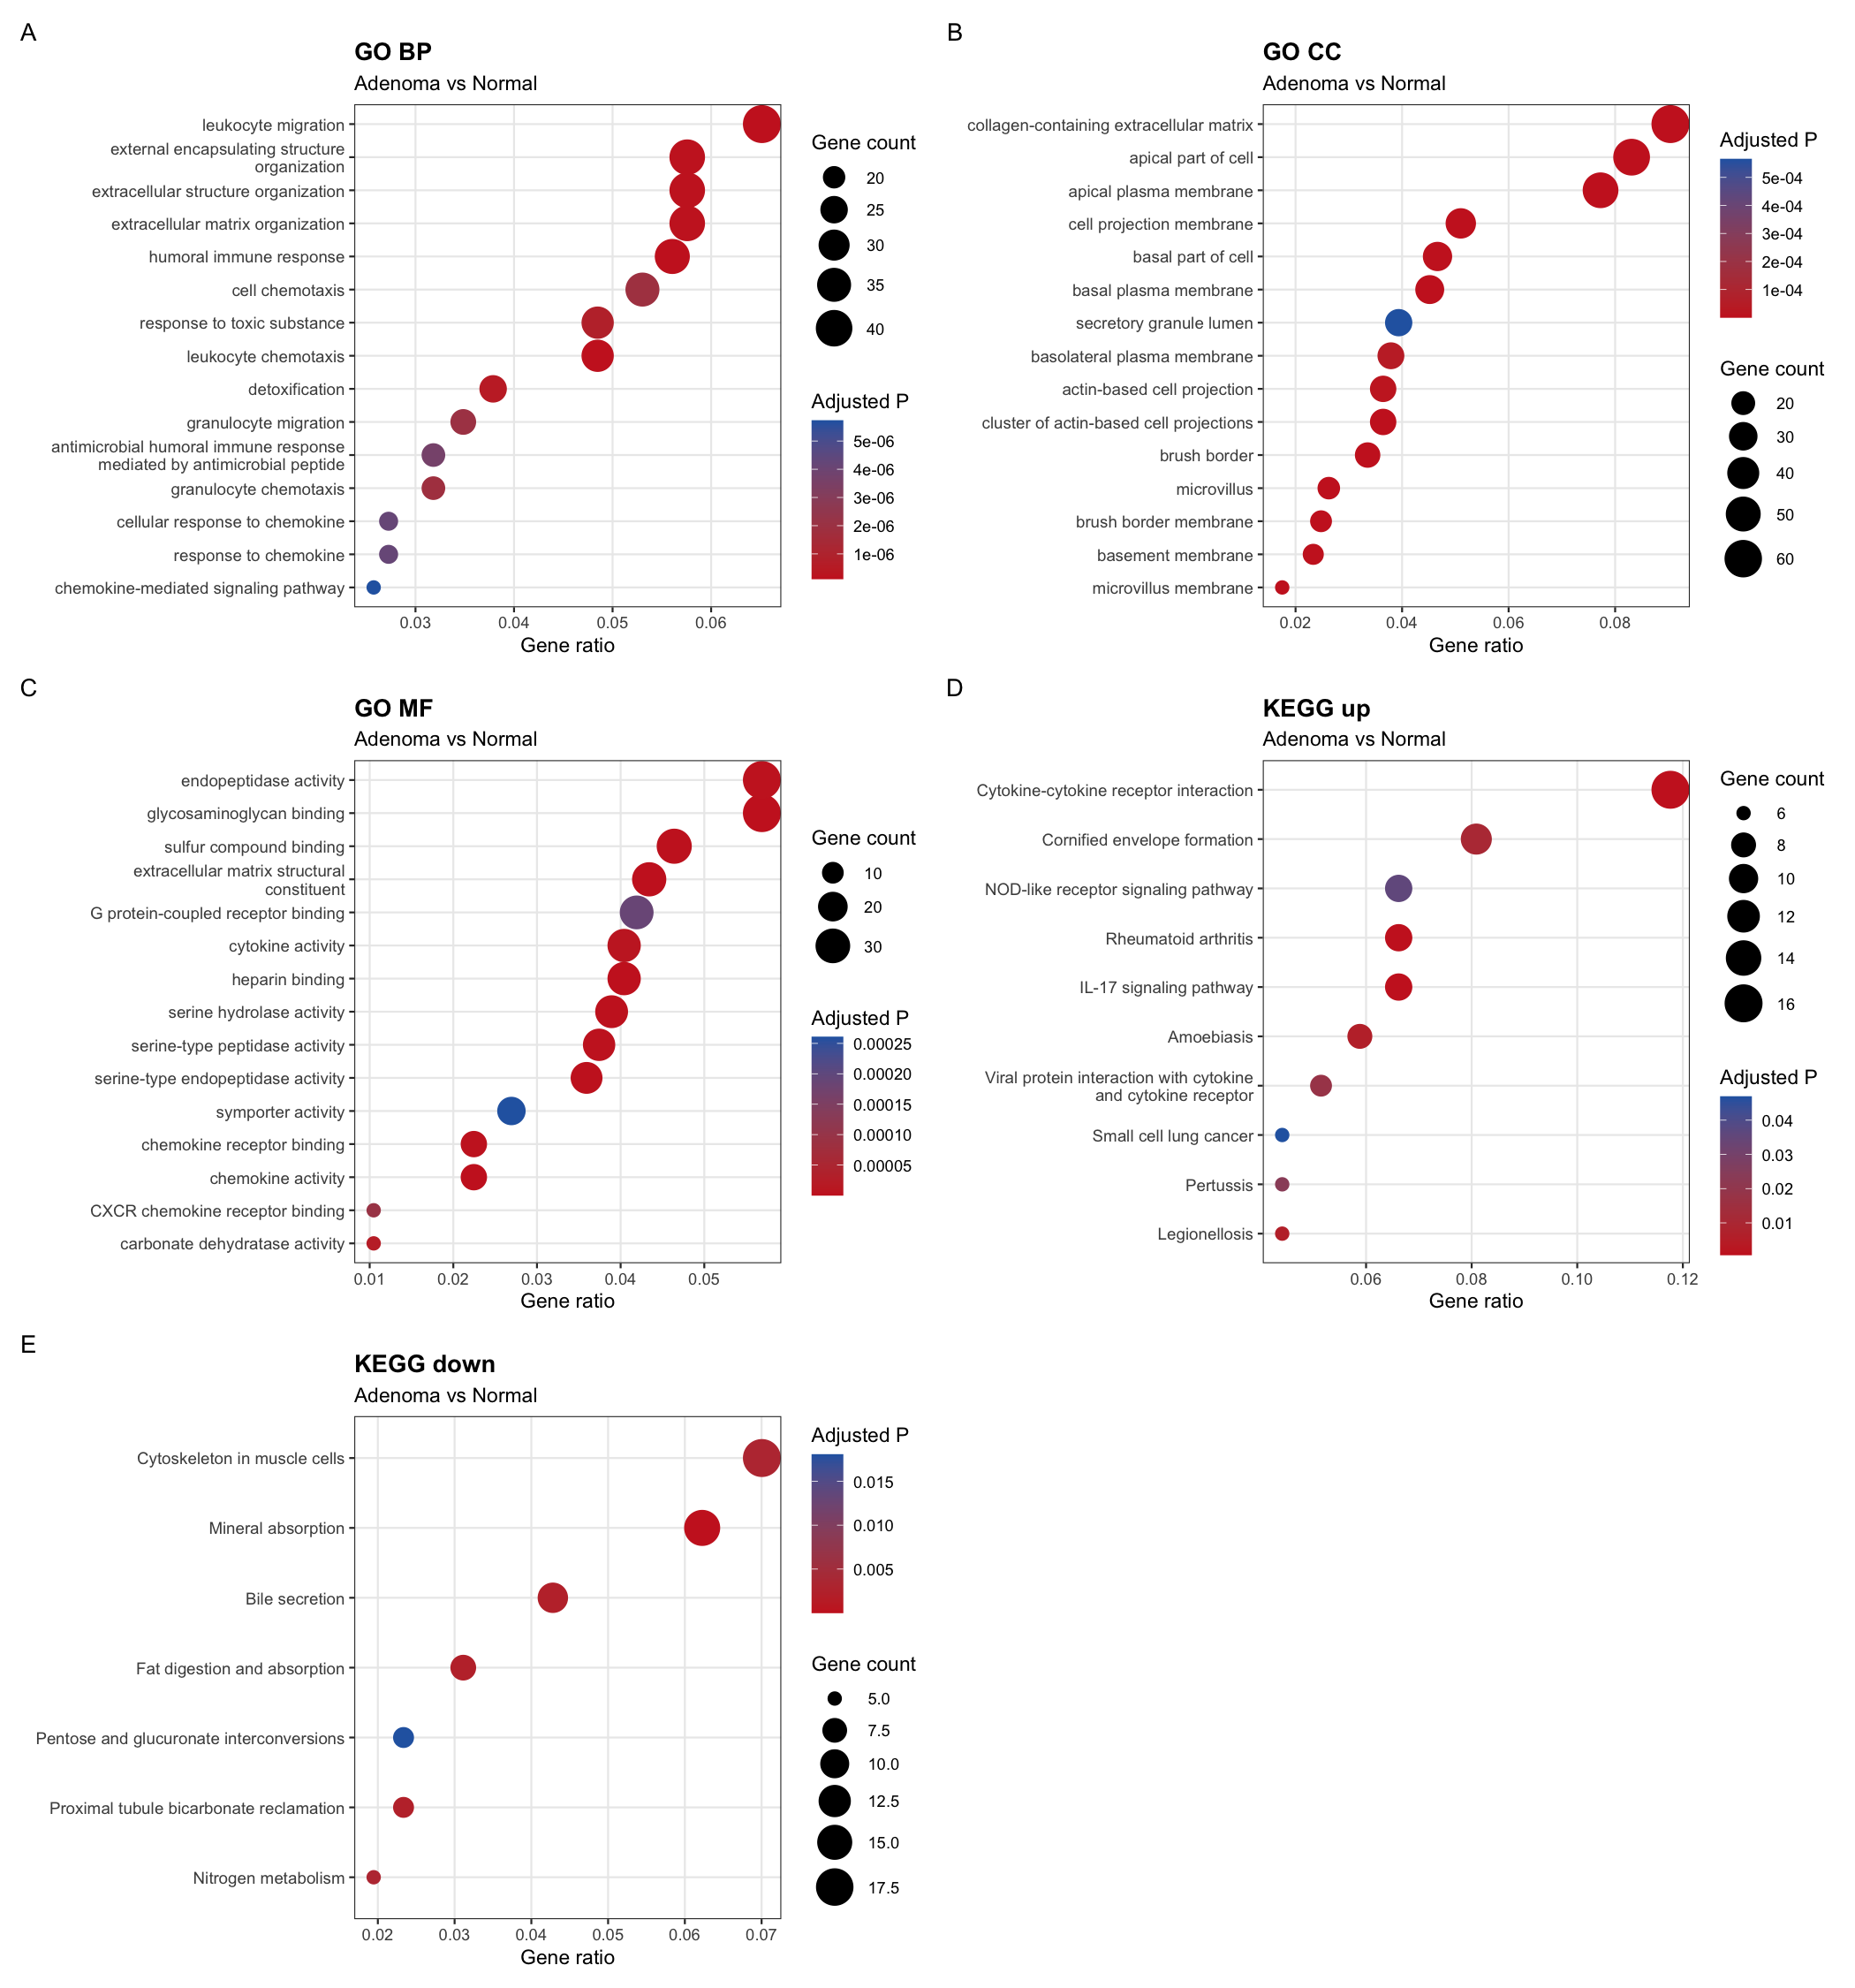

In [13]:
options(repr.plot.width = 14, repr.plot.height = 15)
plot_enrichment("Adenoma_vs_Normal")

### Carcinoma versus adenoma
I apply the same plotting rules to the carcinoma-adenoma comparison for Figure 4. Collagen fibril organization and extracellular-matrix organization are prominent, with contributions from collagen genes, FAP and POSTN. The pathway results add focal adhesion and cell-cycle activity. Compared with the adenoma-normal findings, this places greater emphasis on matrix remodeling and proliferation during the transition to carcinoma.

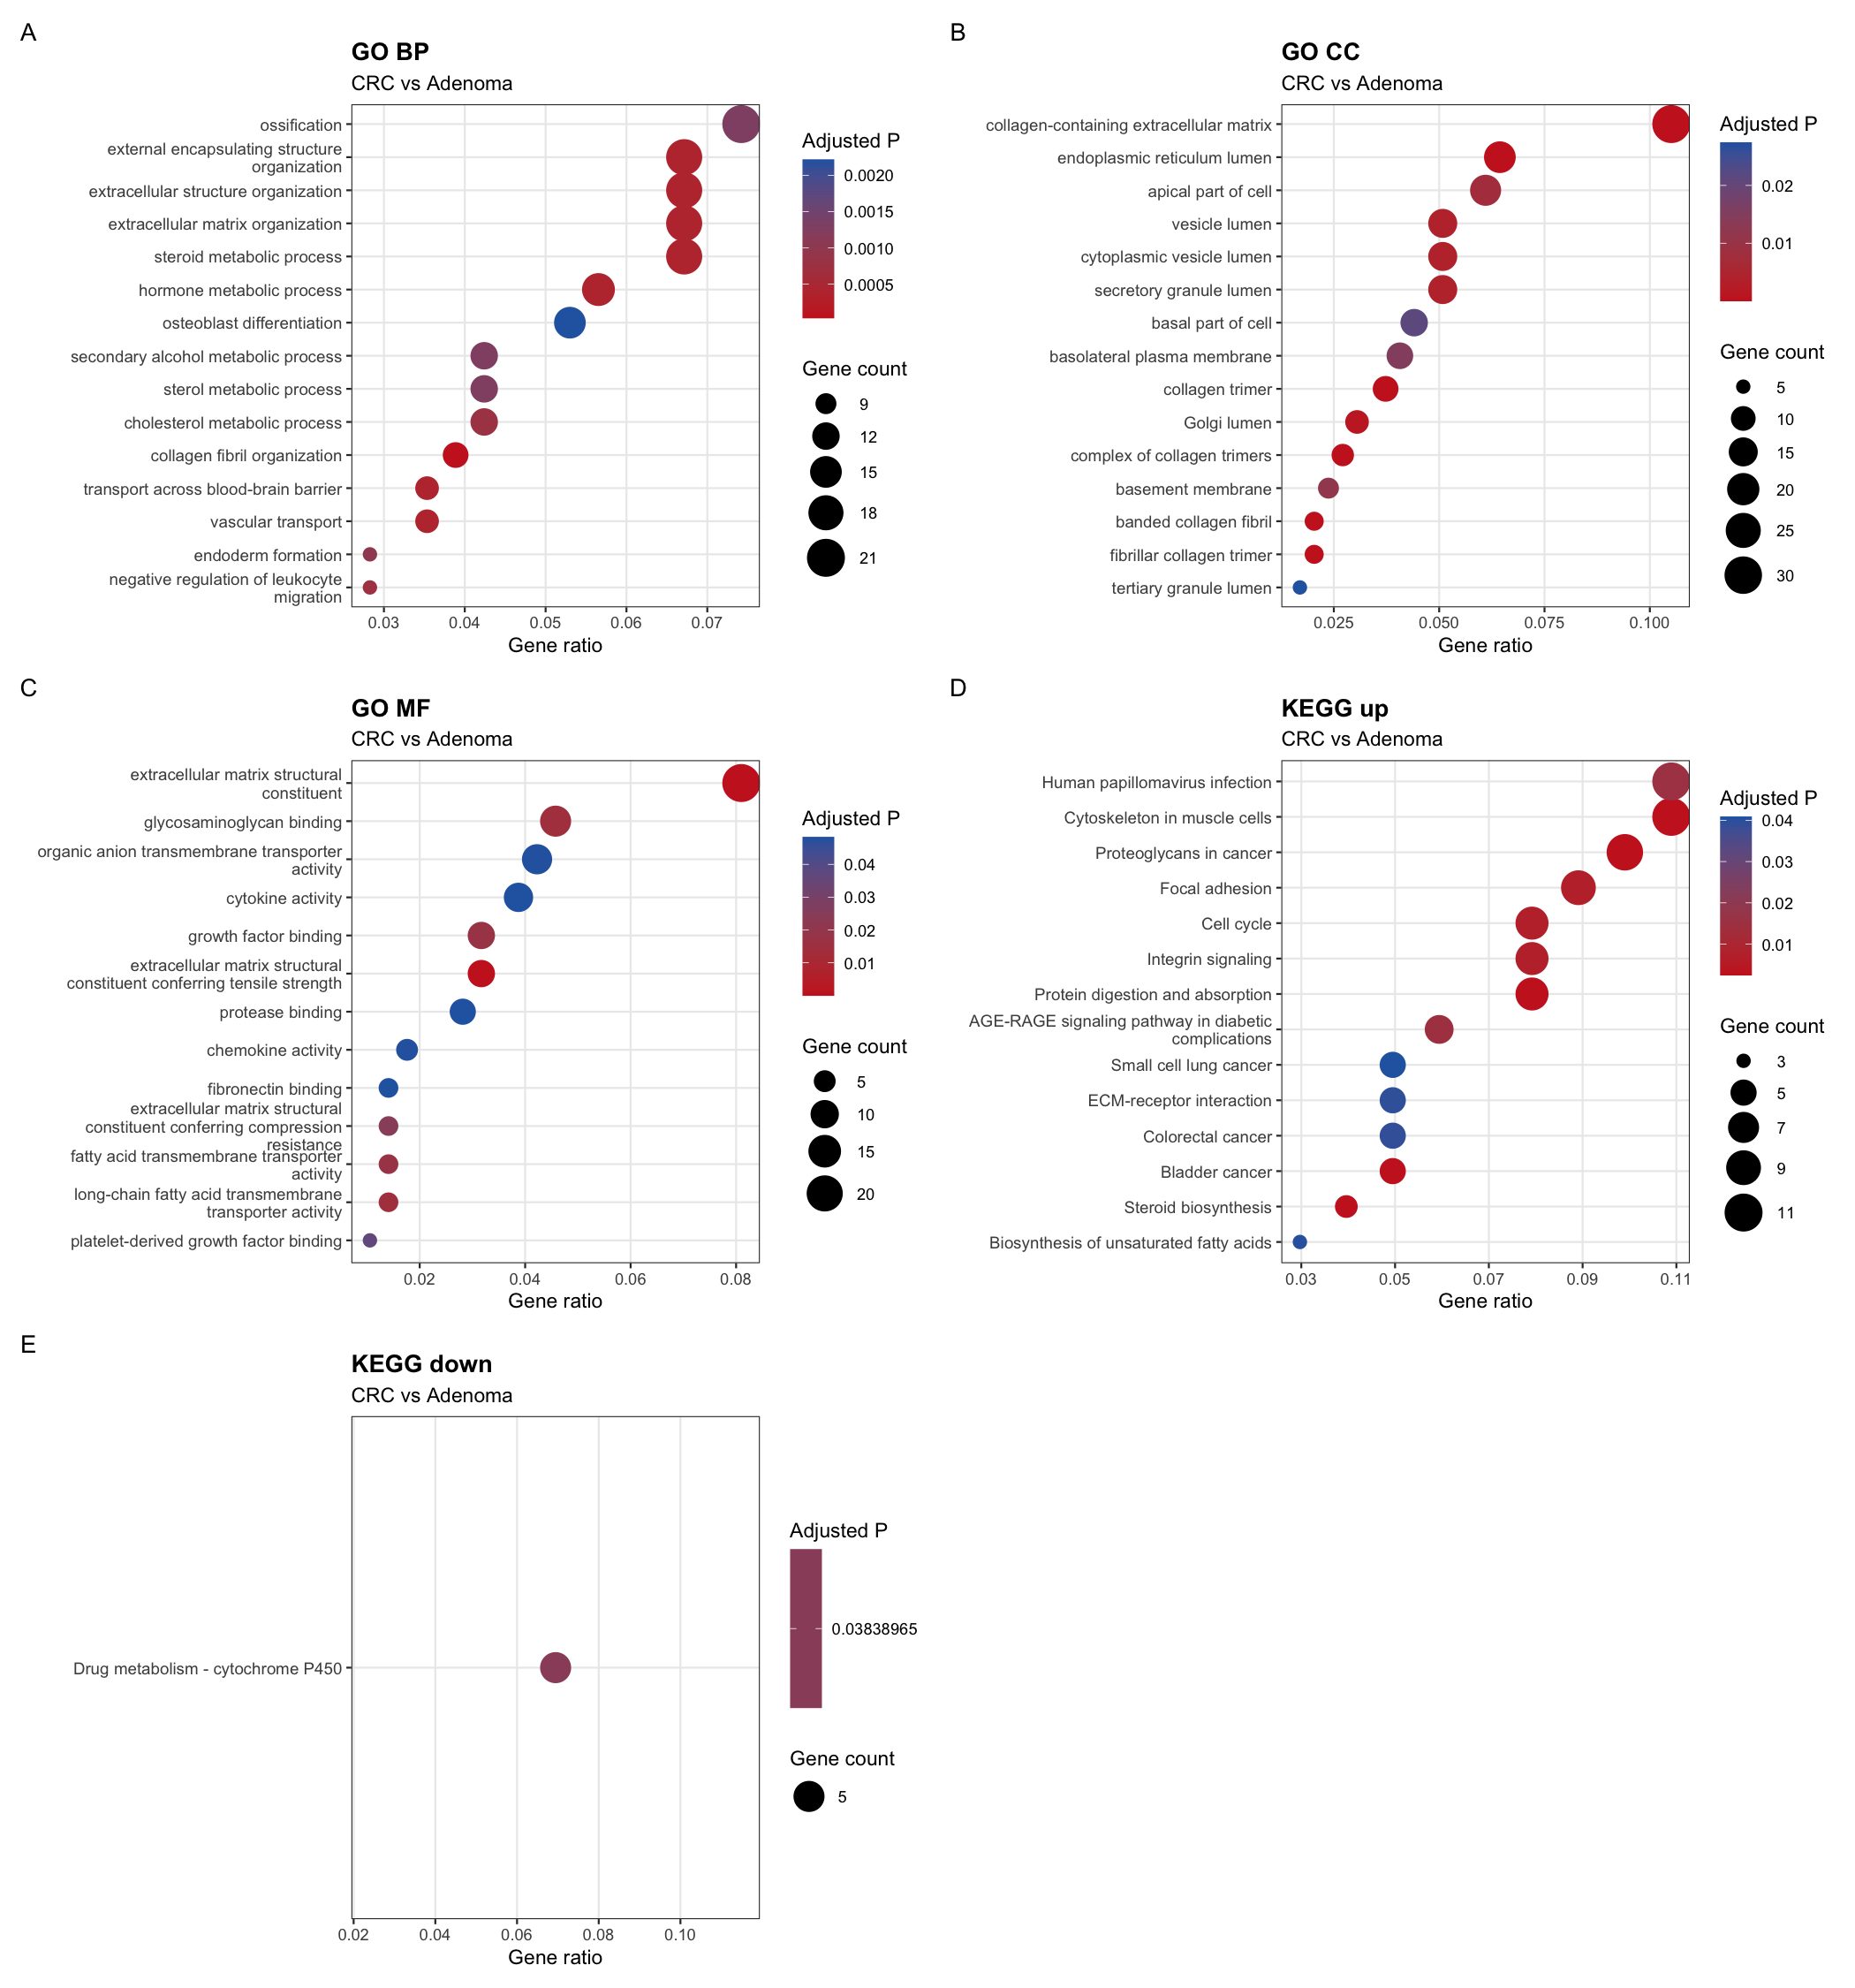

In [14]:
options(repr.plot.width = 14, repr.plot.height = 15)
plot_enrichment("CRC_vs_Adenoma")

<a id="protein-network"></a>
## Protein network
I use STRING to ask whether the 29 progression-associated proteins share functional relationships. The protein network contains 29 nodes and 61 associations; my manuscript reports 28 expected associations and PPI enrichment P = 2.99 x 10^-8. This connects the individual expression changes into a biological network and helps identify proteins for structural follow-up. The Python script recalculates centrality from the archived edges and checks the observed compound-disease distances against the saved results.

In [15]:
network_log <- system2(python, c("scripts/python/network_analysis.py", "--mode", "validate"),
                        stdout = TRUE, stderr = TRUE)
if (!is.null(attr(network_log, "status"))) stop(paste(network_log, collapse = "\n"))
nodes <- read.csv("results/network/ppi_centrality_recalculated.csv")
show_table(head(nodes[, c("name", "degree", "betweenness", "closeness")], 10),
           "Ten highest-degree proteins")

name,degree,betweenness,closeness
MYC,13,0.298,0.657
CXCL8,13,0.261,0.657
GPT,8,0.096,0.590
UGT1A10,8,0.051,0.561
PPARGC1A,8,0.036,0.548
ADH1C,7,0.136,0.469
TNFRSF17,7,0.083,0.511
FABP2,6,0.102,0.523
CXCL2,6,0.055,0.535
HSD17B2,6,0.030,0.523


### Progression-associated protein network
I use the original STRING export for Figure 5A. It retains the website's colored protein nodes, structure thumbnails and evidence-channel lines. Its 29 node labels and 61 edges match the archived analysis tables. The display script composites the original transparent image onto white and checks the archived SVG against those tables.

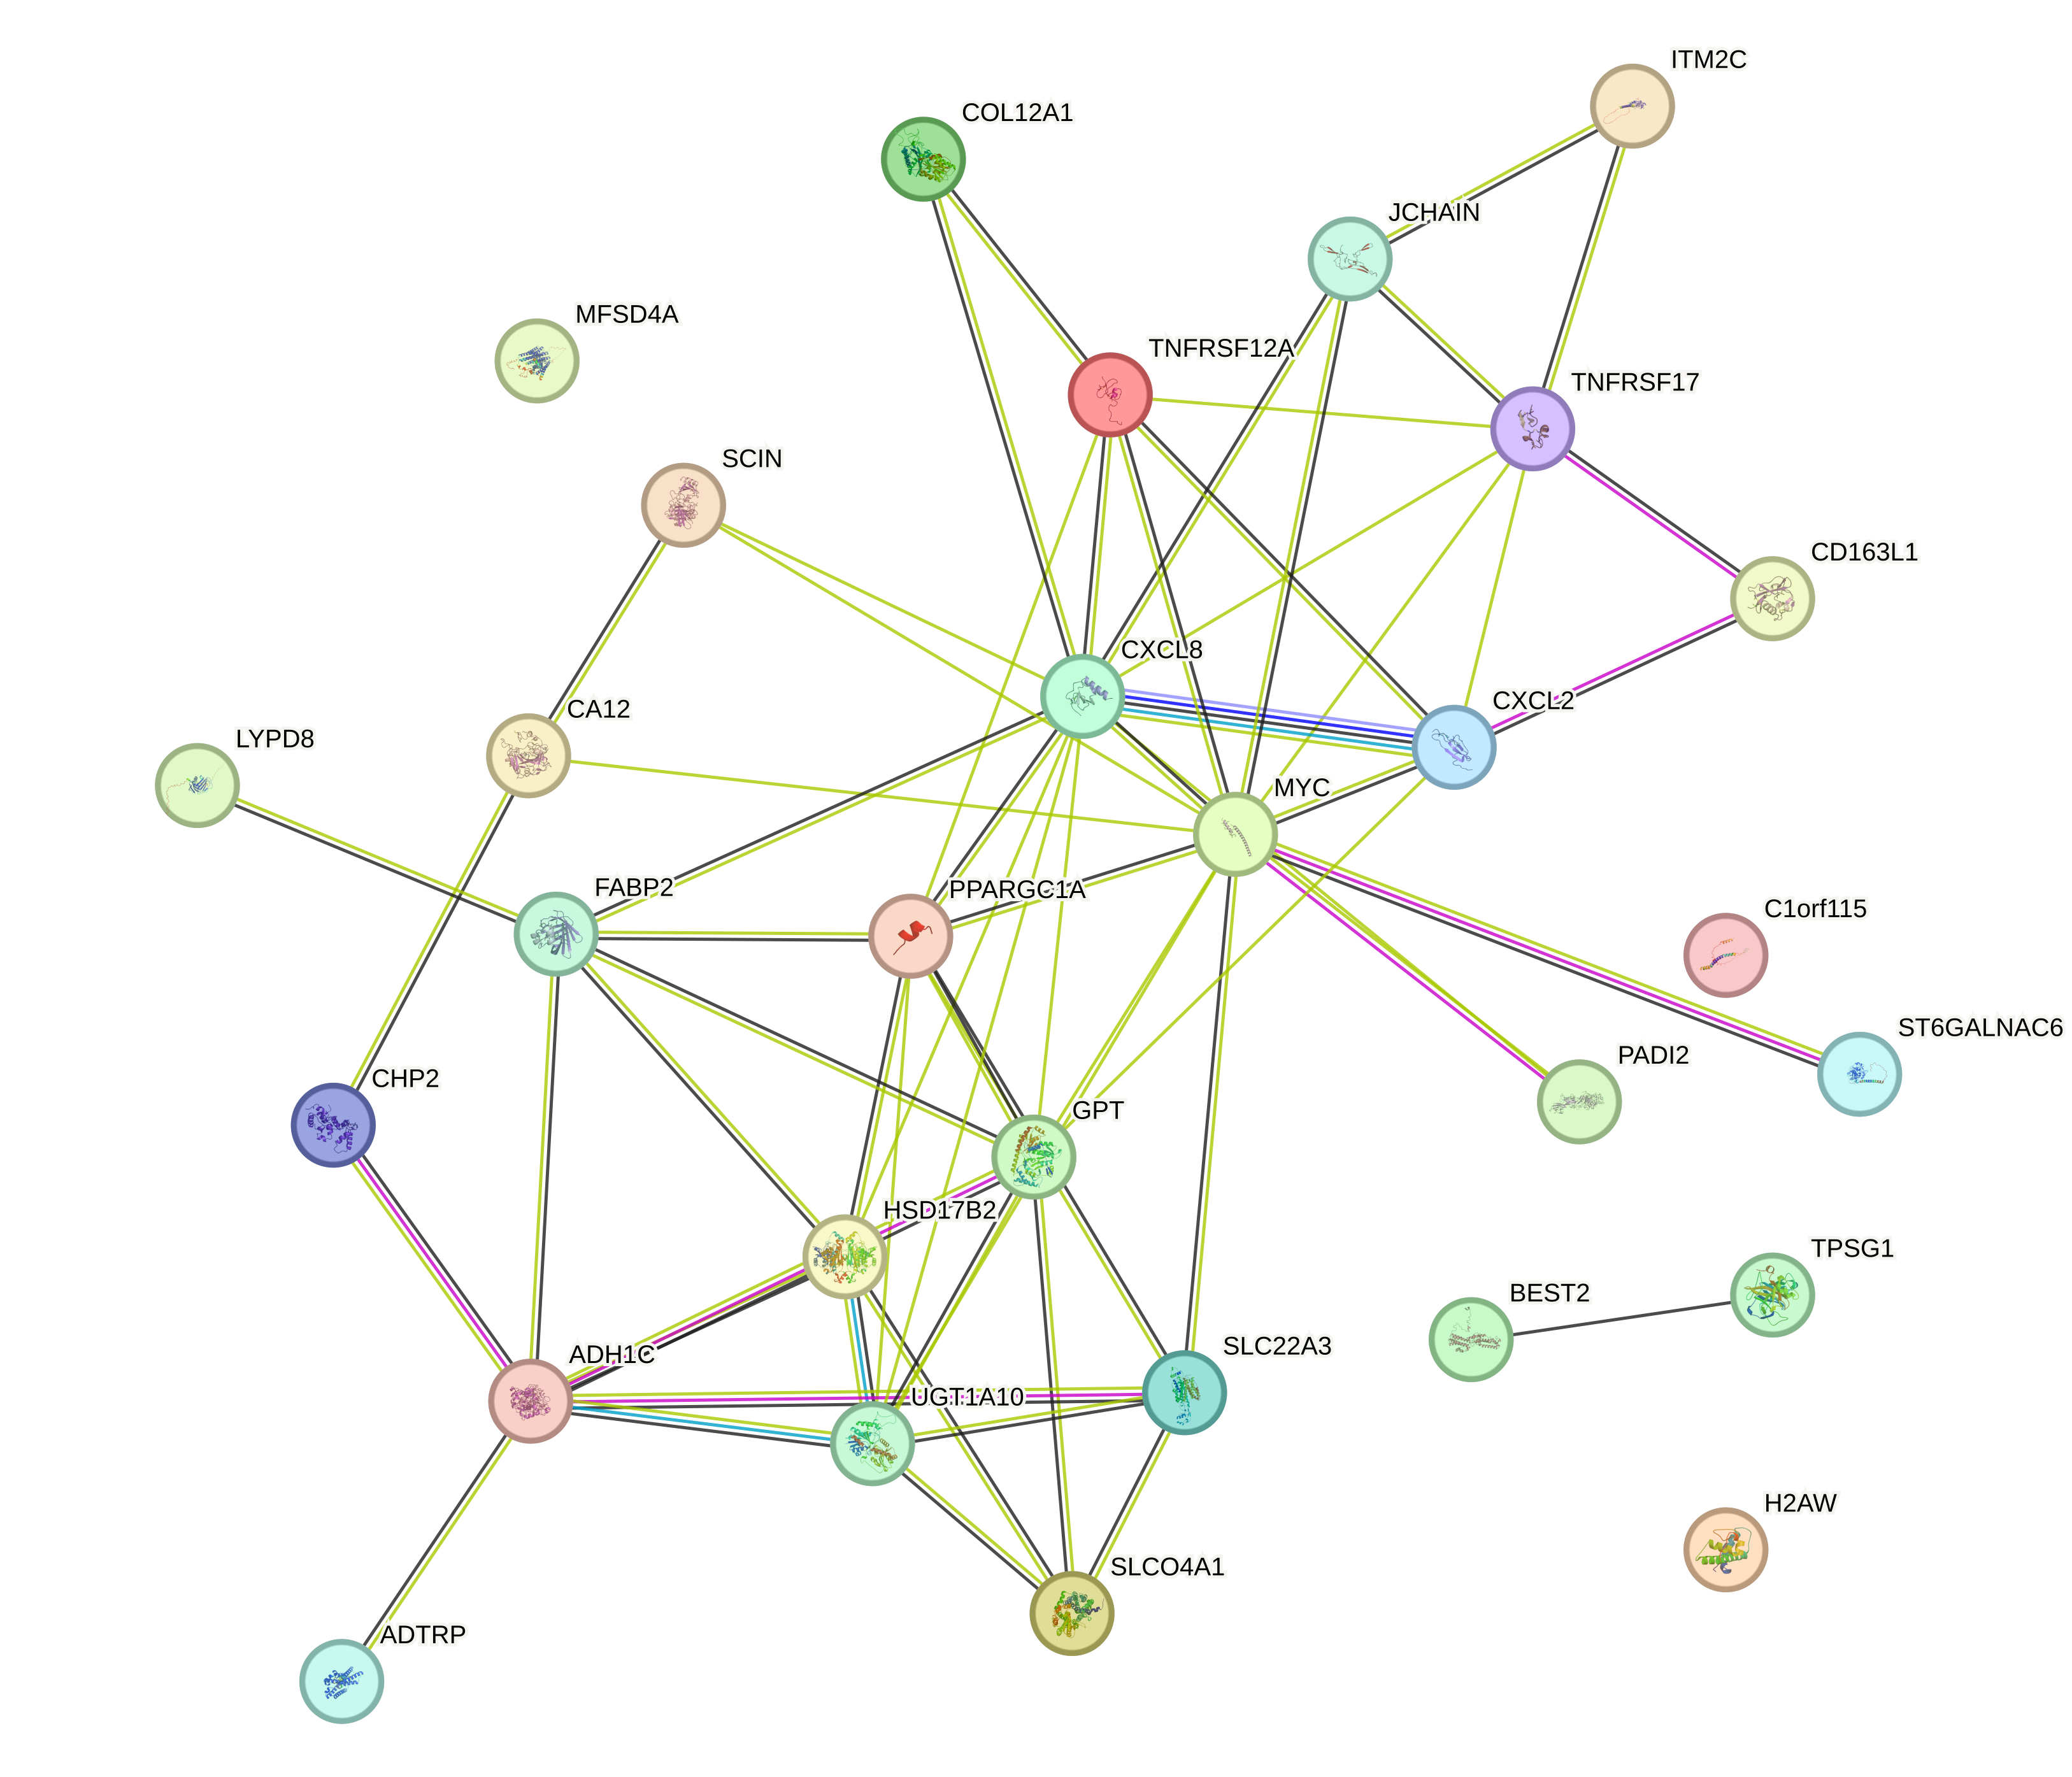

In [16]:
string_visual_log <- system2(python, c("scripts/build_string_visuals.py", "--offline"),
                              stdout = TRUE, stderr = TRUE)
if (!is.null(attr(string_visual_log, "status"))) stop(paste(string_visual_log, collapse = "\n"))
IRdisplay::display_png(file = "figures/reproduced/network/string_native/progression_ppi_string.png")

### Protein centrality
I compare degree, betweenness and closeness for the ten highest-degree proteins. Degree counts direct connections; betweenness and closeness describe each protein's position within its connected component. MYC and CXCL8 each have 13 connections, the highest degree in this network. ADH1C has seven. These results later contribute to the choice of CXCL8 and ADH1C for docking, together with the availability of experimental structures.

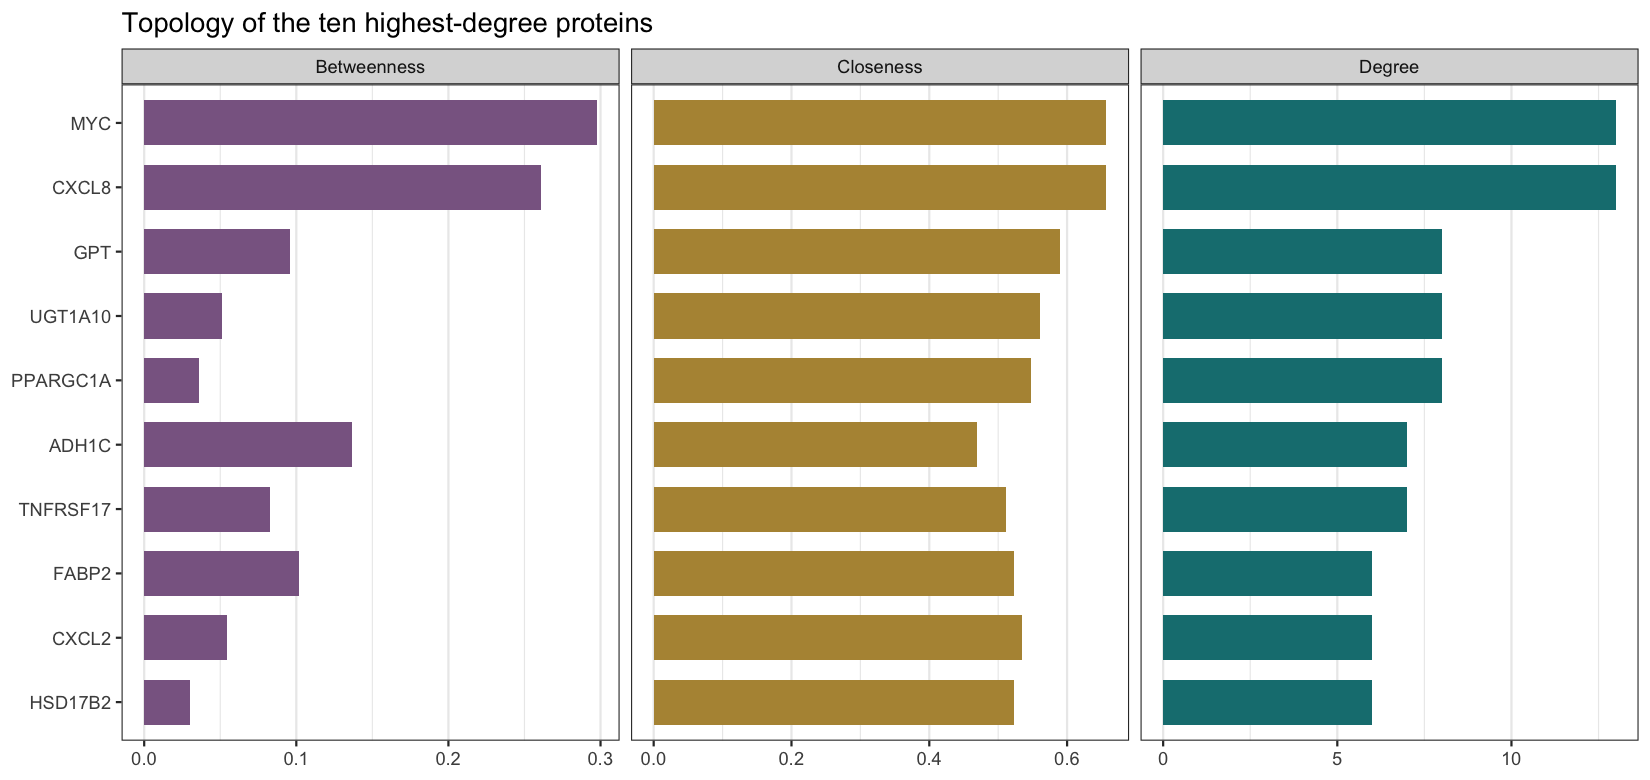

In [17]:
options(repr.plot.width = 11, repr.plot.height = 5.2)
top <- nodes[order(-nodes$degree, -nodes$betweenness, nodes$name), ][1:10, ]
metrics <- rbind(data.frame(name = top$name, metric = "Degree", value = top$degree),
                 data.frame(name = top$name, metric = "Betweenness", value = top$betweenness),
                 data.frame(name = top$name, metric = "Closeness", value = top$closeness))
metrics$name <- factor(metrics$name, levels = rev(top$name))
centrality <- ggplot(metrics, aes(value, name, fill = metric)) +
  geom_col(width = 0.7) + facet_wrap(~metric, scales = "free_x", nrow = 1) +
  scale_fill_manual(values = c(Betweenness = "#8A6792", Closeness = "#B49342", Degree = "#157D80")) +
  labs(title = "Topology of the ten highest-degree proteins", x = NULL, y = NULL) +
  theme_bw(base_size = 11) +
  theme(legend.position = "none", panel.grid.major.y = element_blank())
centrality

<a id="polyphenol-prioritization"></a>
## Polyphenol prioritization
I examine whether the recorded targets of a compound lie unusually close to the disease-associated proteins in the human interactome. This links the progression-associated expression results to candidate compounds while allowing a compound to act through neighboring proteins. The expression analysis above retains 29 genes, and the archived proximity calculation maps 24 disease nodes into that interactome. I recalculate the observed distances and recover the historical Z scores from the saved null-distribution means and standard deviations.

### Proximity across the compound records
Figure 6A shows the closest-distance Z scores for all 66 recorded entries. The dashed lines mark Z = -1.96 and Z = 1.96.

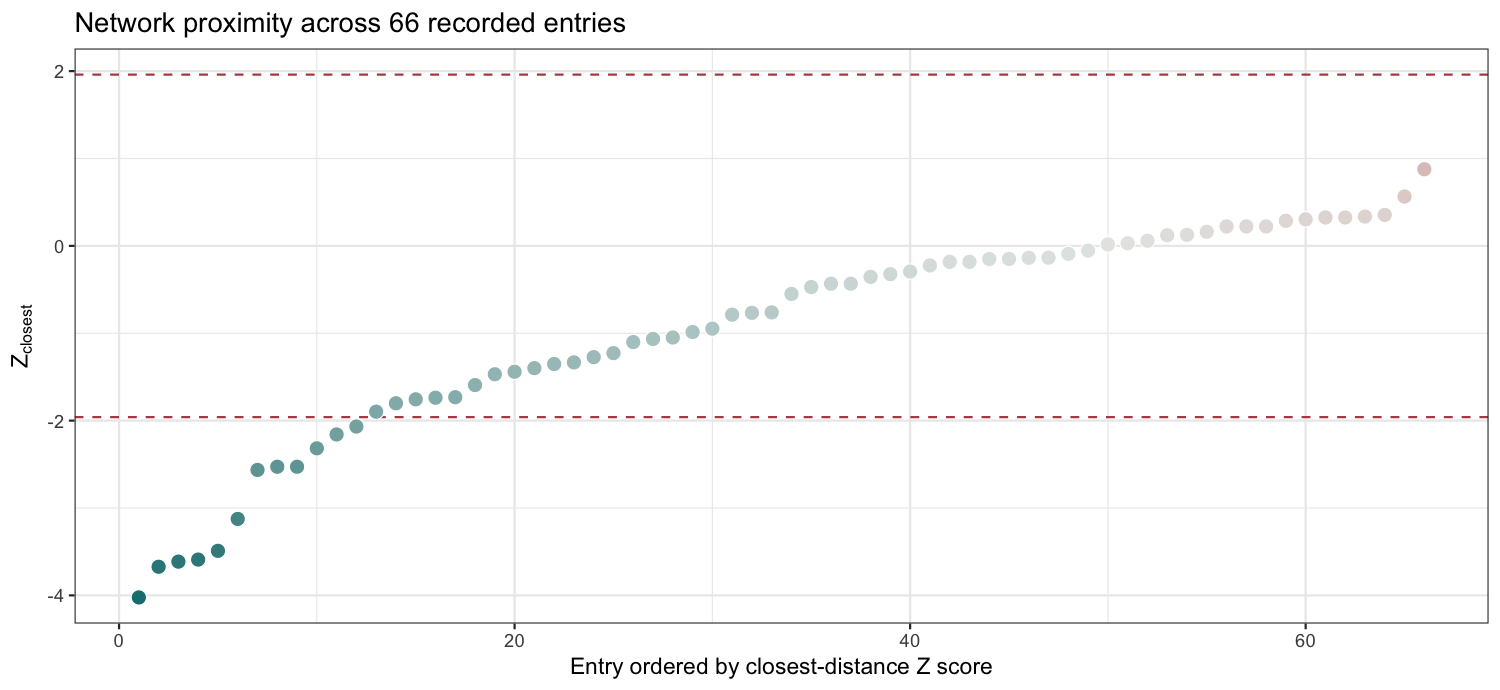

In [18]:
options(repr.plot.width = 10, repr.plot.height = 4.6)
all_records <- read.csv("results/network/proximity_all_66_records.csv")
all_records <- all_records[order(all_records$z_closest), ]
all_records$record_rank <- seq_len(nrow(all_records))
distribution <- ggplot(all_records, aes(record_rank, z_closest)) +
  geom_hline(yintercept = c(-1.96, 1.96), color = "#B34C50", linetype = "dashed") +
  geom_point(aes(fill = z_closest), shape = 21, size = 3.2, color = "white", stroke = 0.4) +
  scale_fill_gradient2(low = "#157D80", mid = "#E5E8E6", high = "#B34C50", midpoint = 0) +
  labs(title = "Network proximity across 66 recorded entries",
       x = "Entry ordered by closest-distance Z score", y = expression(Z[closest])) +
  theme_bw(base_size = 11) + theme(legend.position = "none")
distribution

### The ten highest-ranked compounds
The 66 recorded names correspond to 65 PubChem identities. Eleven identities fall below Z = -1.96. I rank the unique identities by the closest-distance Z score and retain the first ten.

In [19]:
top10 <- read.csv("results/network/top10_candidates.csv")
show_table(top10[, c("rank", "display_name", "pubchem_cid", "z_closest", "n_mapped_chemical")],
           "Ten prioritized compounds")

rank,display_name,pubchem_cid,z_closest,n_mapped_chemical
1,kaempferol,5280863,-4.023,37
2,4-methylcatechol,9958,-3.672,2
3,quercetin,5280343,-3.614,216
4,punicalagin,16129869,-3.590,1
5,umbelliferone,5281426,-3.490,3
6,esculetin,5281416,-3.125,1
7,"2,3-dihydroxybenzoic acid",19,-2.564,1
8,trans-resveratrol,445154,-2.528,63
9,"1,4-naphthoquinone",8530,-2.317,4
10,phloretin,4788,-2.158,2


Kaempferol is the highest-ranked compound, with a closest-distance Z score of approximately -4.02. Its recorded targets are closer to the disease-associated proteins than expected under the archived randomization model. In Figure 6B, the horizontal position gives -Z, and the point size gives the number of mapped targets. The labels retain the signed Z scores. I carry the ten highest-ranked unique identities forward to chemical characterization and docking, linking the structural assessment to a defined network screen.

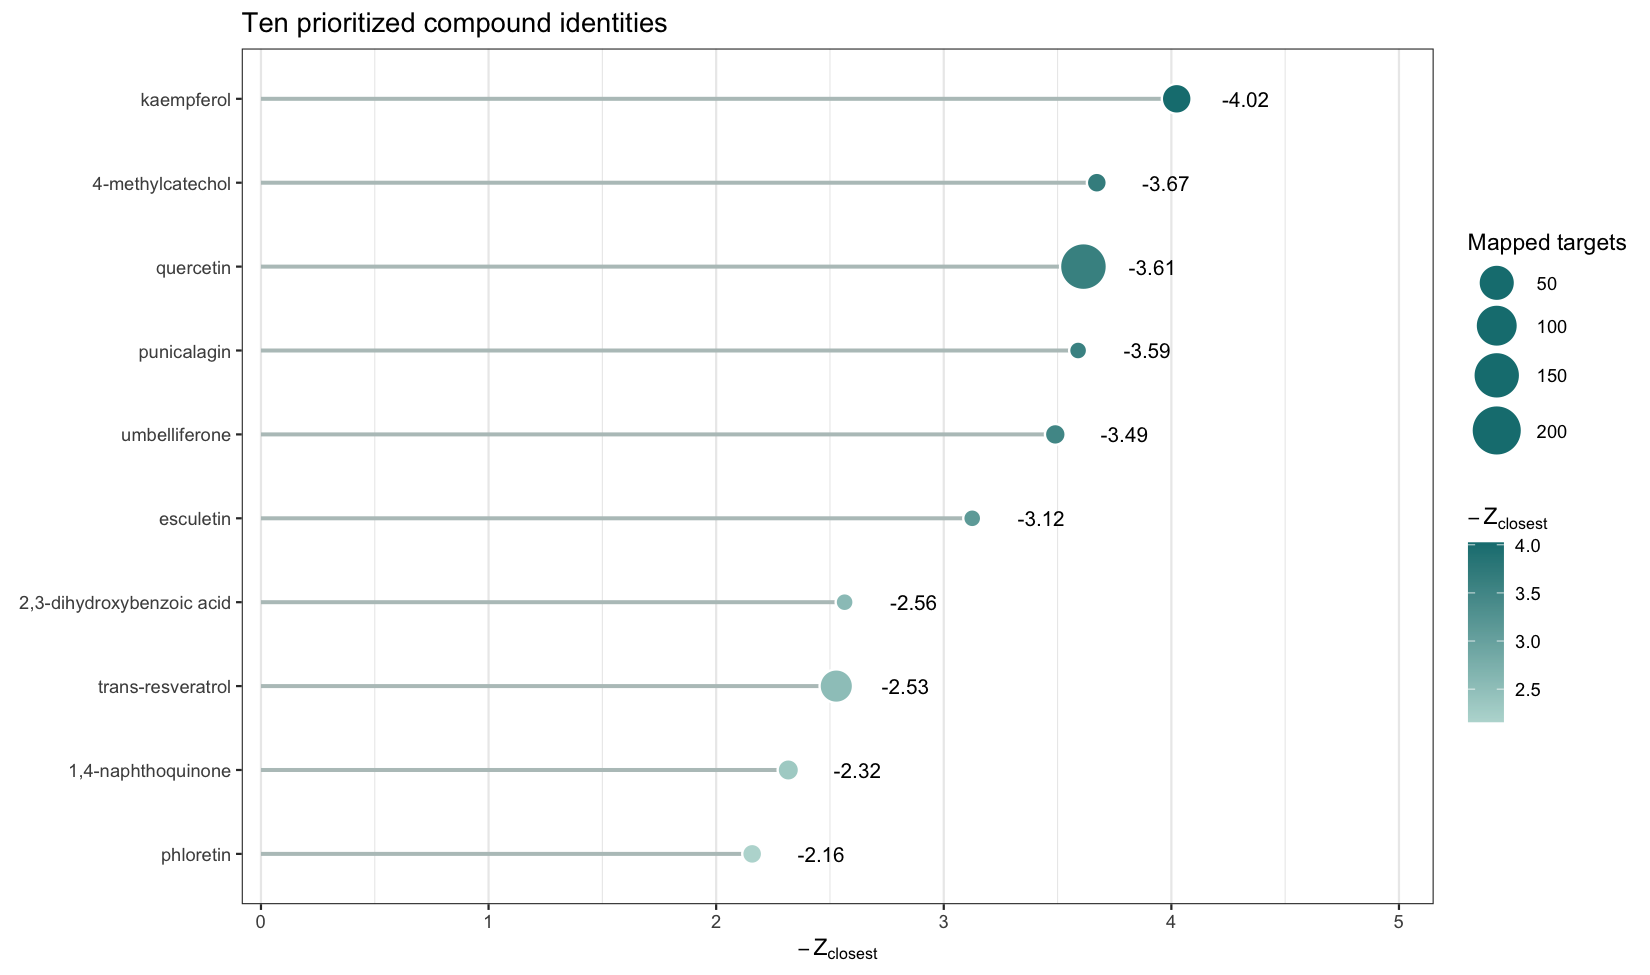

In [20]:
options(repr.plot.width = 11, repr.plot.height = 6.5)
top10 <- read.csv("results/network/top10_candidates.csv")
top10$display_name <- factor(top10$display_name, levels = rev(top10$display_name))
lollipop <- ggplot(top10, aes(-z_closest, display_name)) +
  geom_segment(aes(xend = 0, yend = display_name), linewidth = 0.9, color = "#B7C4C3") +
  geom_point(aes(size = n_mapped_chemical, fill = -z_closest),
              shape = 21, color = "white", stroke = 0.8) +
  geom_text(aes(label = sprintf("%.2f", z_closest)), nudge_x = 0.2, hjust = 0, size = 3.5) +
  scale_size_continuous(range = c(3.5, 10), name = "Mapped targets",
                        guide = guide_legend(override.aes = list(fill = "#157D80", color = "#157D80"))) +
  scale_fill_gradient(low = "#B9DAD5", high = "#157D80", name = expression(-Z[closest])) +
  scale_x_continuous(expand = expansion(mult = c(0.02, 0.22))) +
  labs(title = "Ten prioritized compound identities", x = expression(-Z[closest]), y = NULL) +
  theme_bw(base_size = 11) + theme(panel.grid.major.y = element_blank())
lollipop

### Chemical structures
I use the PubChem identifiers to assemble Figure 7 from the cached chemical depictions. This step runs the [structure-assembly script](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/scripts/build_chemical_structures.py) and displays the image it creates.

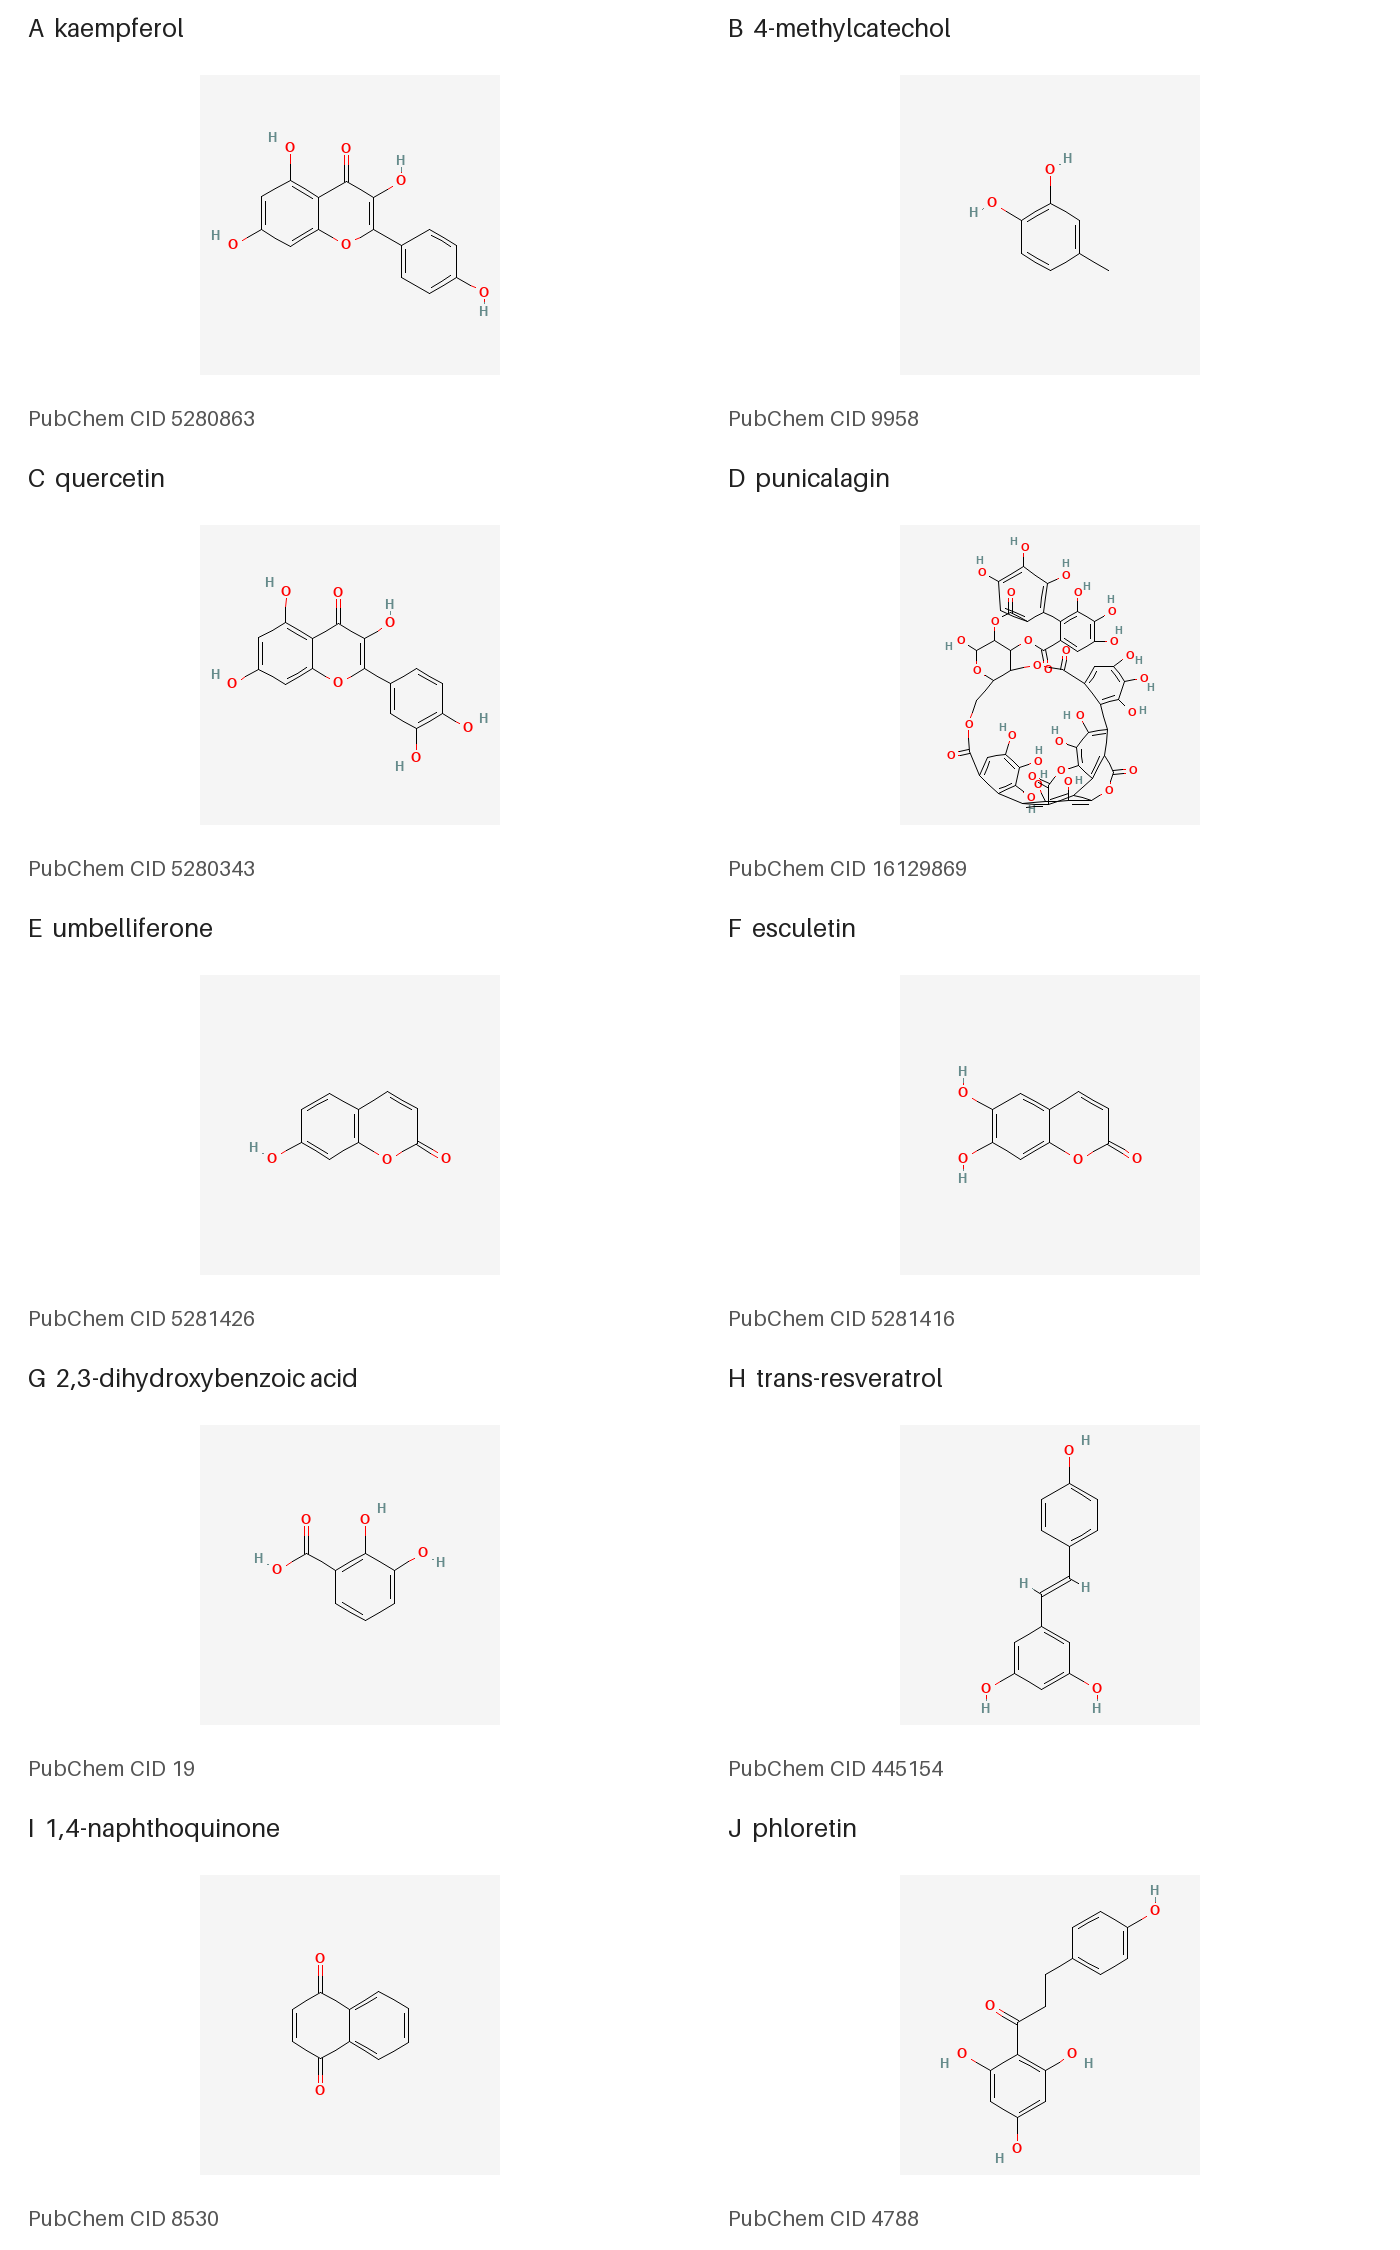

In [21]:
candidates <- read.csv("results/network/top10_candidates.csv")
structure_files <- file.path("data/chemistry/pubchem", paste0("CID_", candidates$pubchem_cid, ".png"))
stopifnot(all(file.exists(structure_files)))
chemistry_log <- system2(python, "scripts/build_chemical_structures.py", stdout = TRUE, stderr = TRUE)
if (!is.null(attr(chemistry_log, "status"))) stop(paste(chemistry_log, collapse = "\n"))
IRdisplay::display_png(file = "figures/reproduced/chemistry/figure_07_compound_structures.png")

### Compound target networks
I use cached human STRING 12.0 responses to reconstruct associations among each compound's recorded targets. The query uses functional associations, a combined score cutoff of 0.400, and no added neighbors. I retain native STRING images and check their node and edge sets against the cached data. The table shows how many recorded targets map to STRING and how many edges pass the cutoff.

In [22]:
string_log <- system2(python, c("scripts/python/fetch_string_compounds.py", "--offline"),
                       stdout = TRUE, stderr = TRUE)
if (!is.null(attr(string_log, "status"))) stop(paste(string_log, collapse = "\n"))
compound_info <- read.csv("results/network/compound_string_summary.csv")
show_table(compound_info[, c("display_name", "recorded_targets", "string_mapped_nodes", "edges_score_ge_0_4")],
           "Compound target mapping and network sizes")

display_name,recorded_targets,string_mapped_nodes,edges_score_ge_0_4
kaempferol,40,38,161
4-methylcatechol,2,2,0
quercetin,222,215,1560
punicalagin,1,1,0
umbelliferone,3,3,1
esculetin,1,1,0
"2,3-dihydroxybenzoic acid",1,1,0
trans-resveratrol,64,61,232
"1,4-naphthoquinone",4,4,1
phloretin,2,2,1


### Figure 8A: kaempferol
This native STRING view contains 38 mapped proteins and 161 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/kaempferol.png).

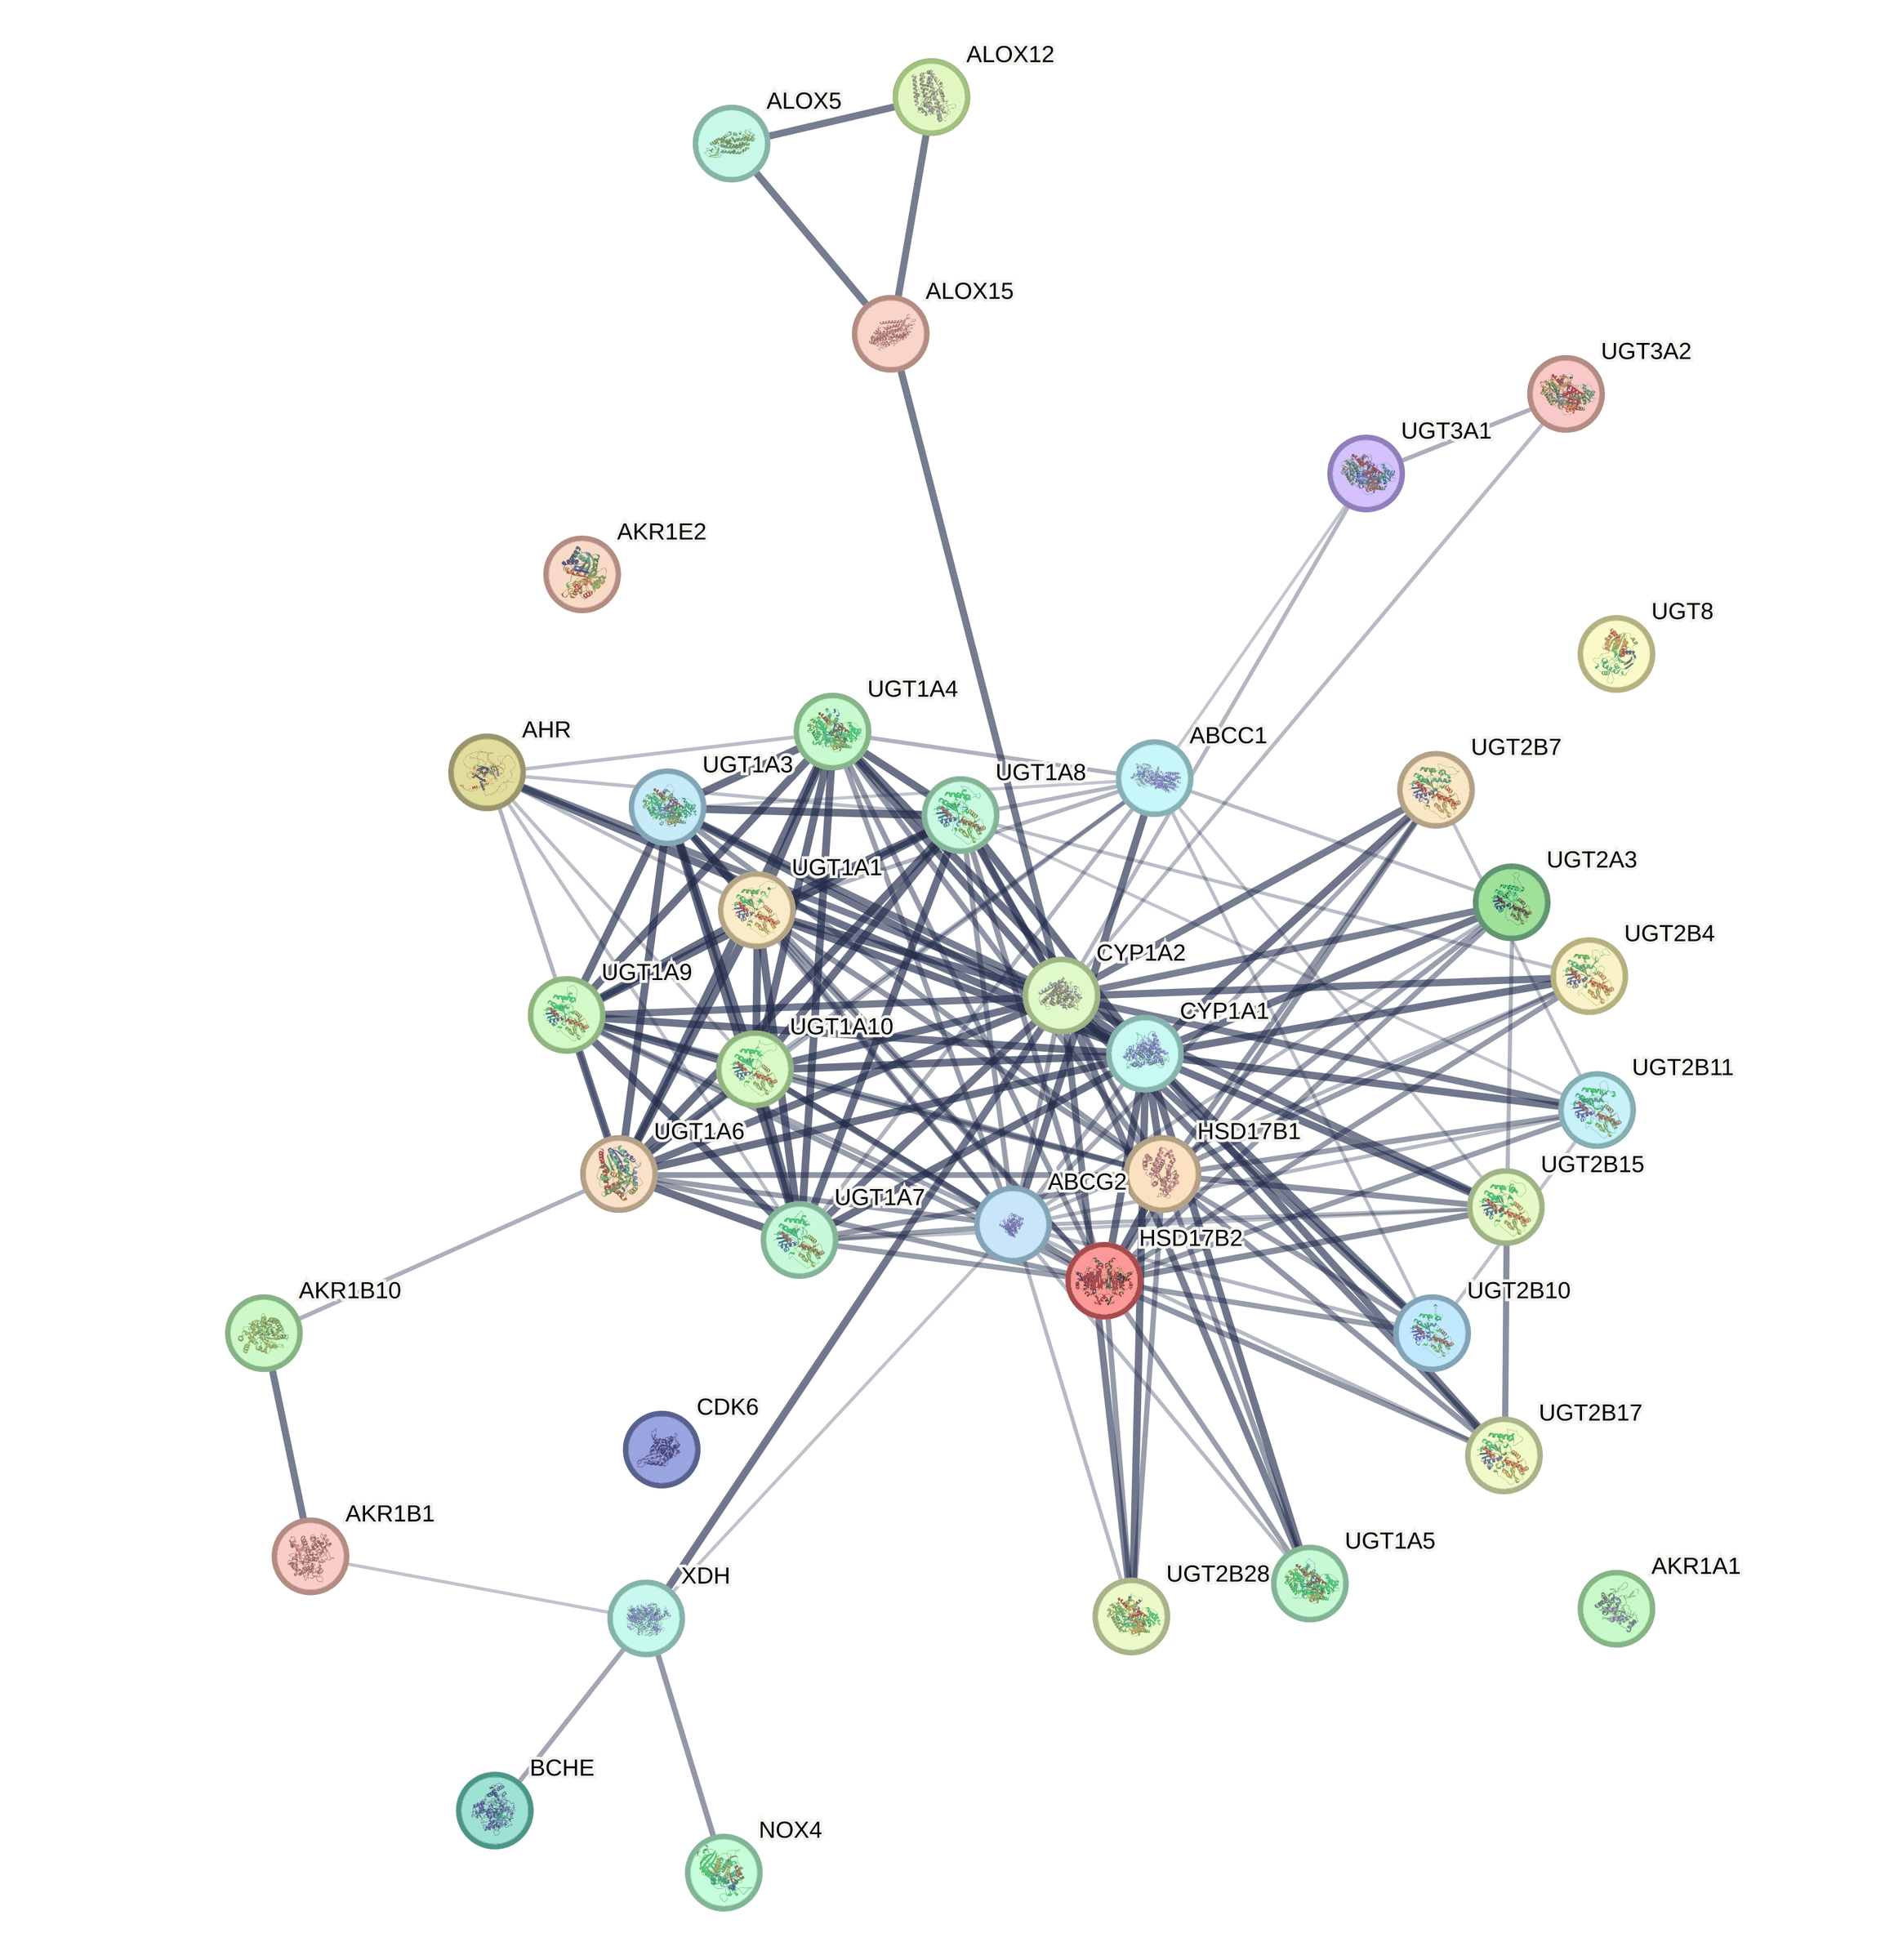

In [23]:
network_image <- "figures/reproduced/network/string_native/kaempferol_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8B: 4-methylcatechol
This native STRING view contains 2 mapped proteins and 0 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/4methylcatechol.png).

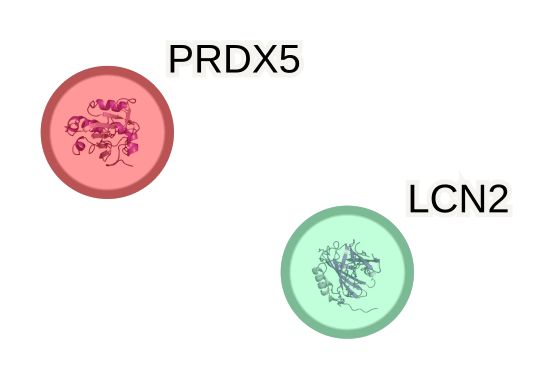

In [24]:
network_image <- "figures/reproduced/network/string_native/4methylcatechol_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8C: quercetin
This native STRING view contains 215 mapped proteins and 1560 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/quercetin.png).

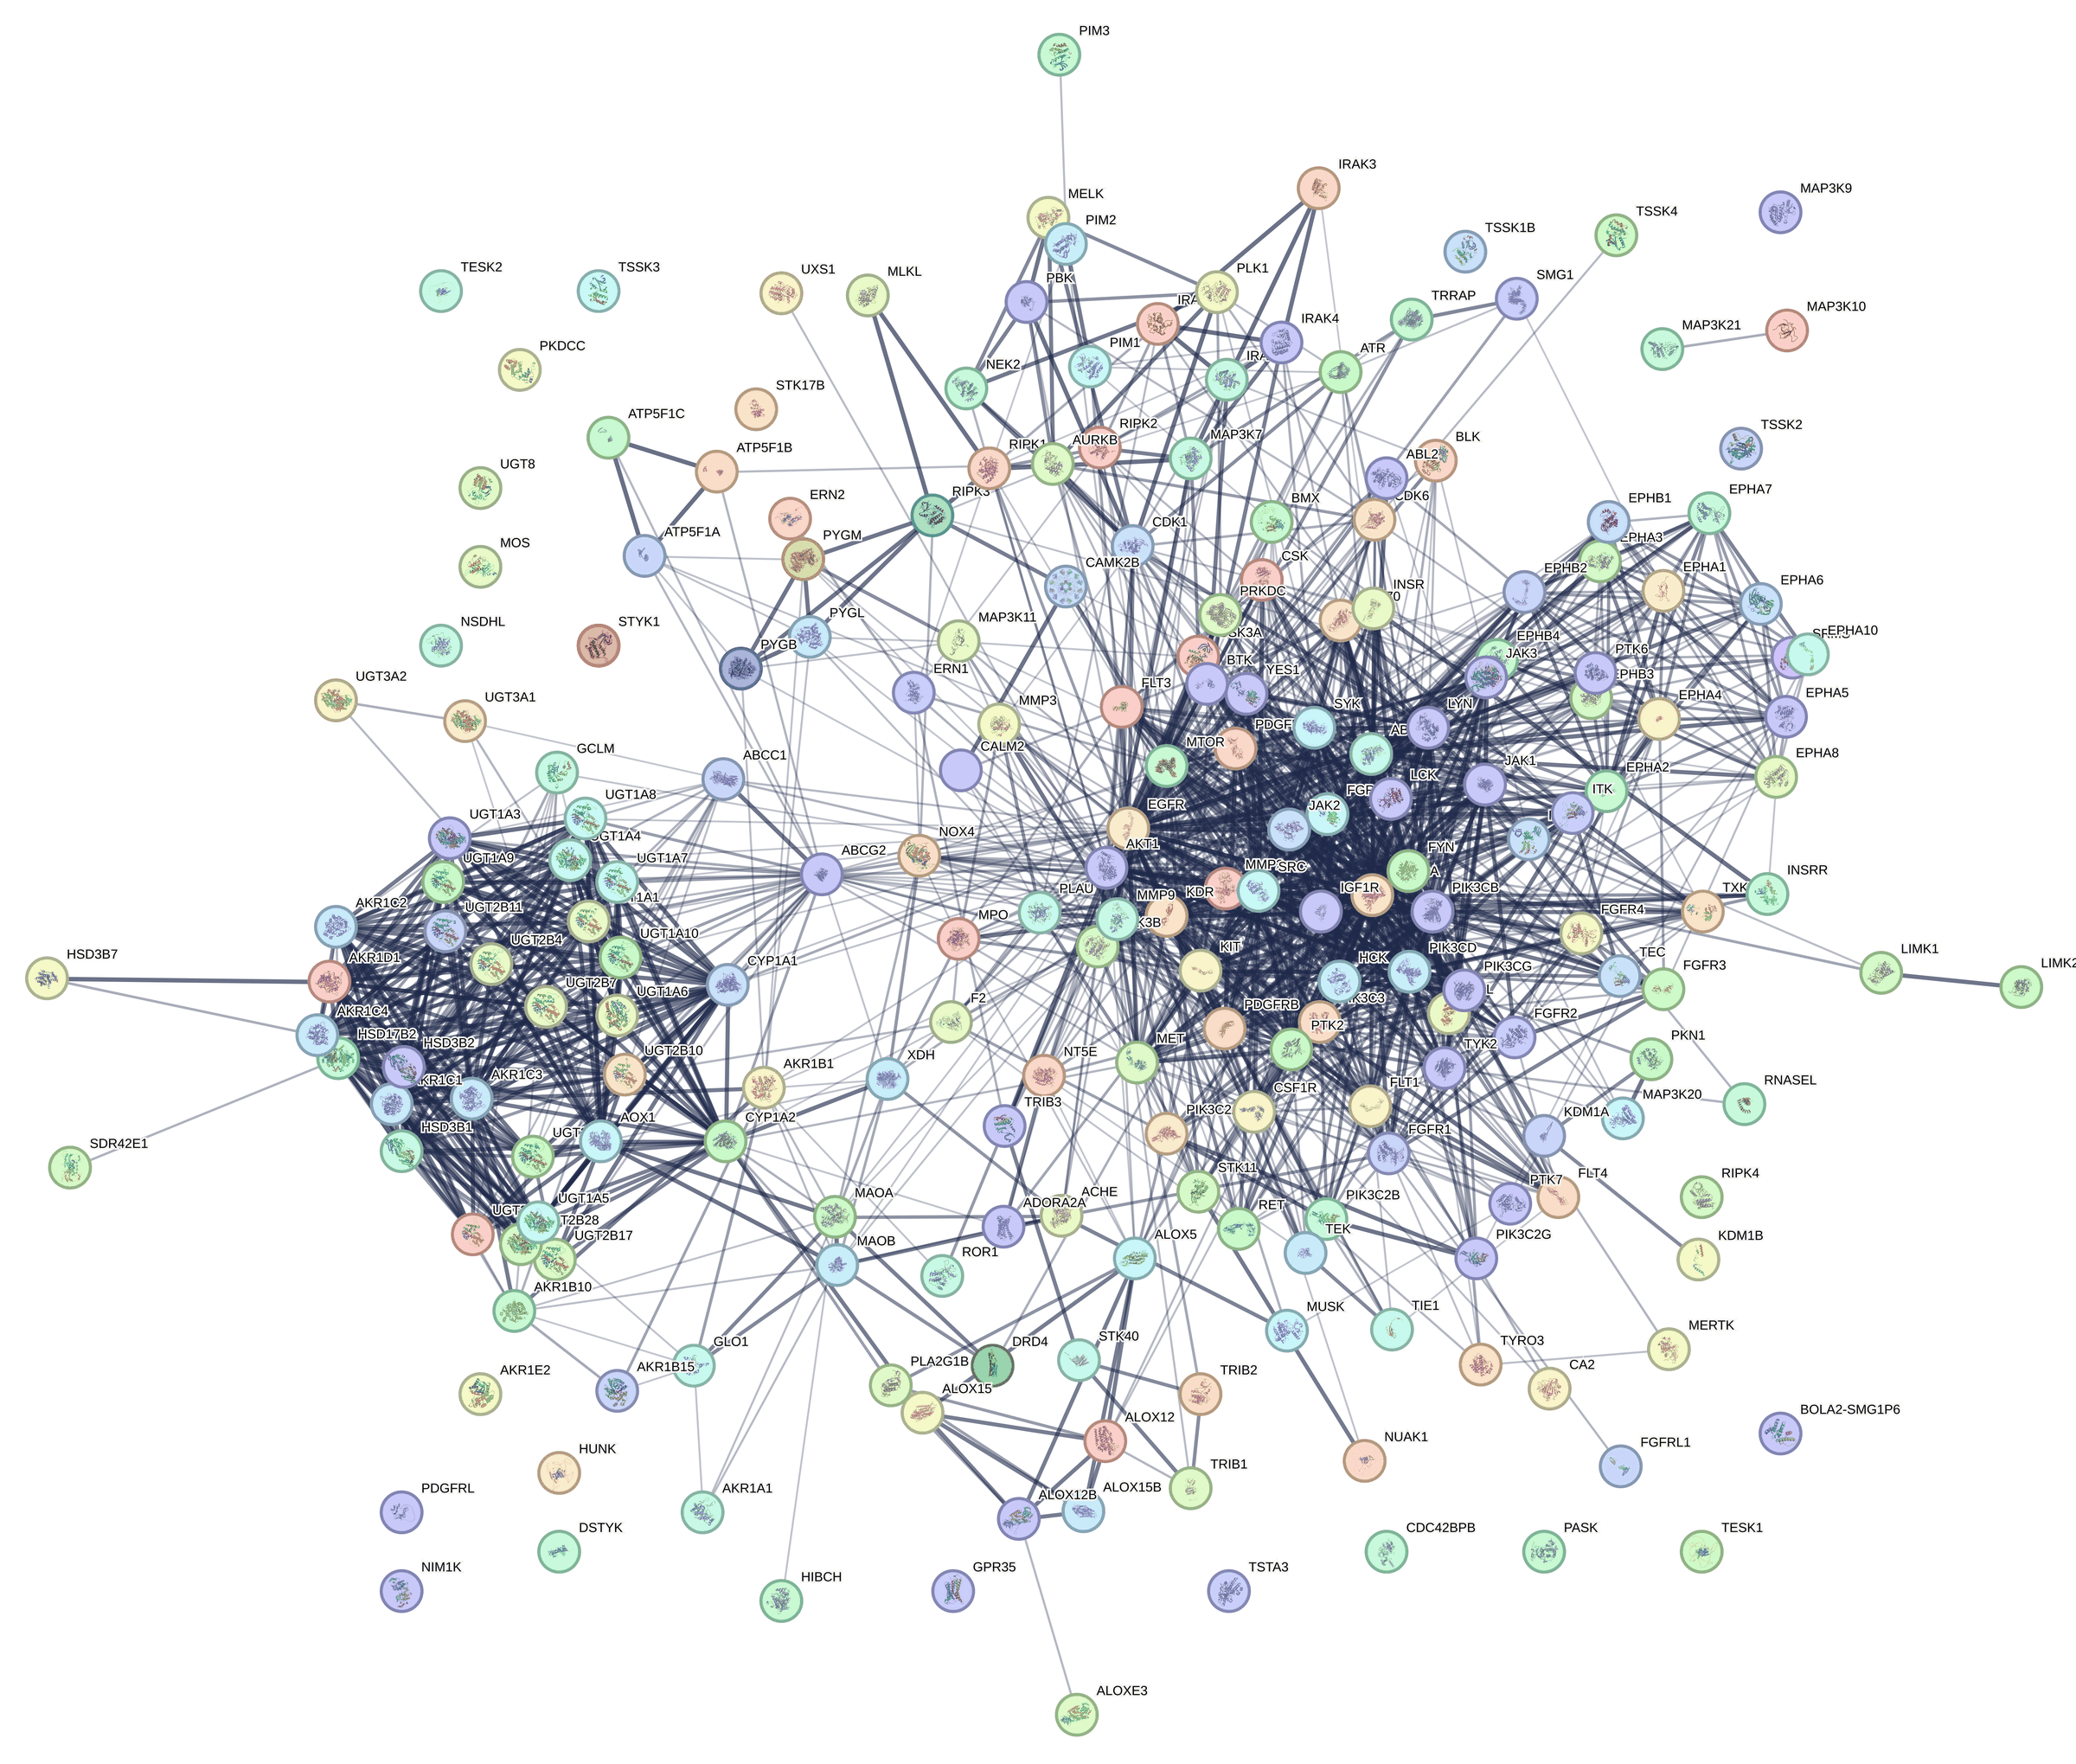

In [25]:
network_image <- "figures/reproduced/network/string_native/quercetin_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8D: punicalagin
This native STRING view contains 1 mapped protein and 0 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/punicalagin.png).

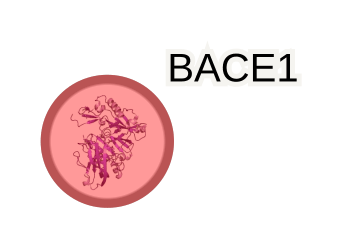

In [26]:
network_image <- "figures/reproduced/network/string_native/punicalagin_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8E: umbelliferone
This native STRING view contains 3 mapped proteins and 1 within-target association. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/umbelliferone.png).

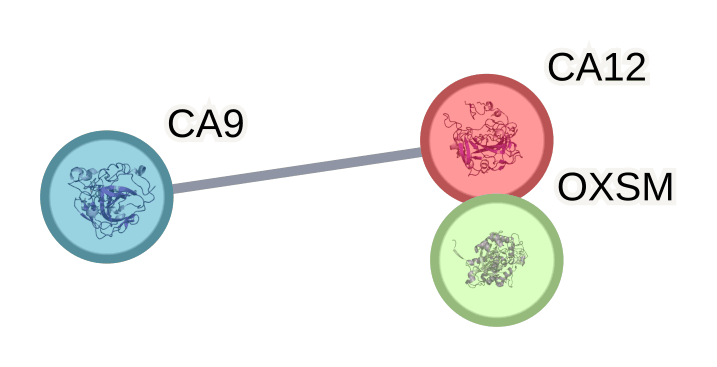

In [27]:
network_image <- "figures/reproduced/network/string_native/umbelliferone_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8F: esculetin
This native STRING view contains 1 mapped protein and 0 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/esculetin.png).

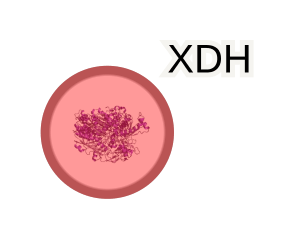

In [28]:
network_image <- "figures/reproduced/network/string_native/esculetin_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8G: 2,3-dihydroxybenzoic acid
This native STRING view contains 1 mapped protein and 0 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/23dihydroxybenzoicacid.png).

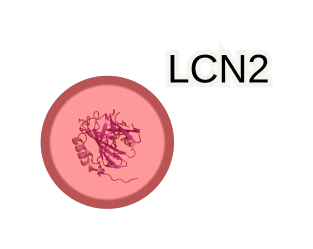

In [29]:
network_image <- "figures/reproduced/network/string_native/23dihydroxybenzoicacid_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8H: trans-resveratrol
This native STRING view contains 61 mapped proteins and 232 within-target associations. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/resveratrol.png).

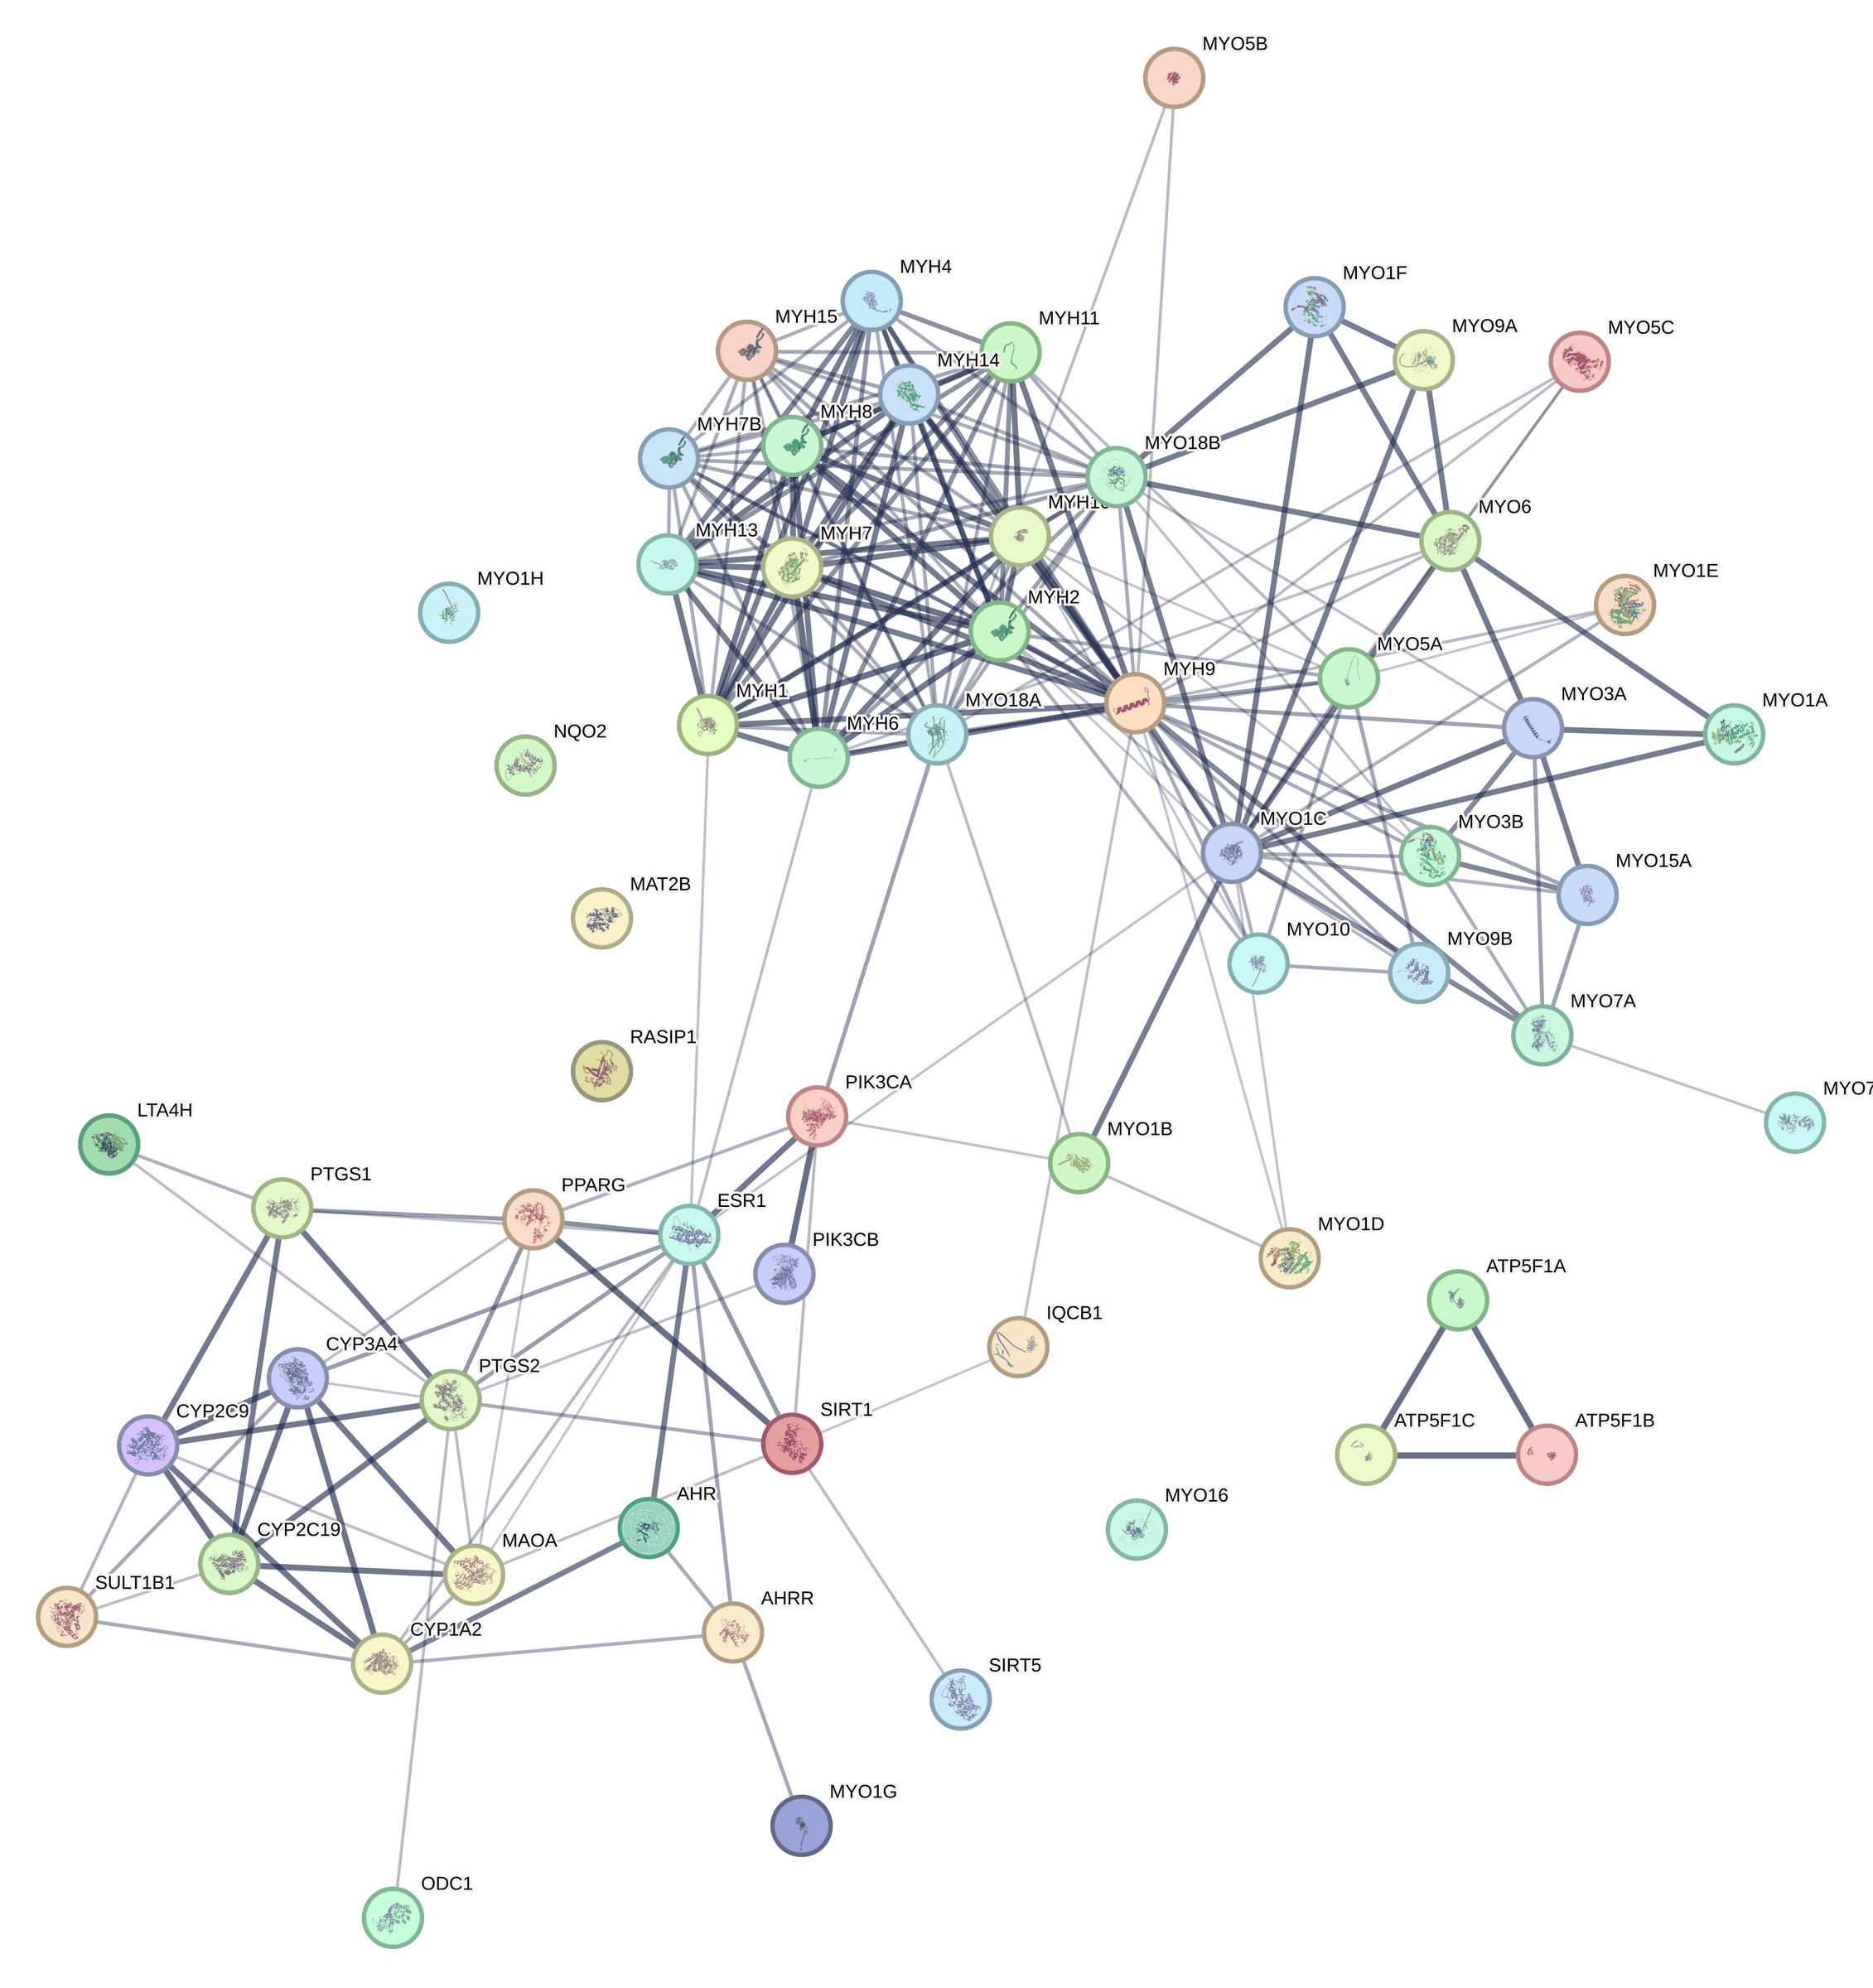

In [30]:
network_image <- "figures/reproduced/network/string_native/resveratrol_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8I: 1,4-naphthoquinone
This native STRING view contains 4 mapped proteins and 1 within-target association. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/14naphtoquinone.png).

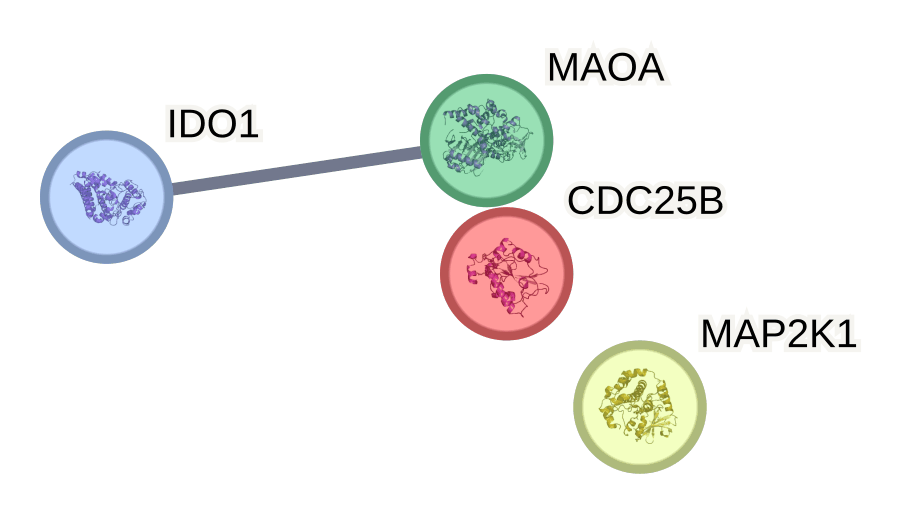

In [31]:
network_image <- "figures/reproduced/network/string_native/14naphtoquinone_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

### Figure 8J: phloretin
This native STRING view contains 2 mapped proteins and 1 within-target association. I show it separately so its labels and protein thumbnails remain readable. Isolated targets are retained. [Full-resolution STRING image](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/figures/reproduced/network/string_native/phloretin.png).

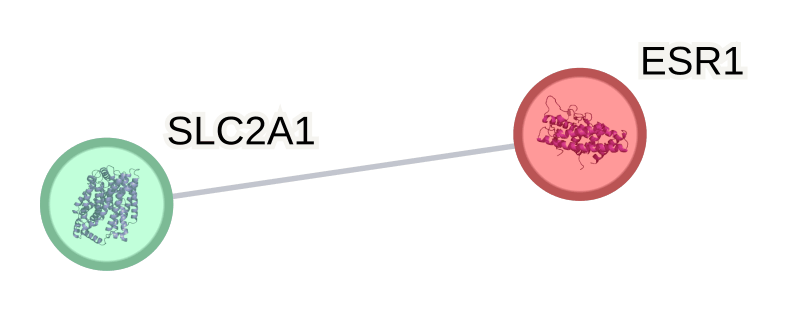

In [32]:
network_image <- "figures/reproduced/network/string_native/phloretin_preview.png"
stopifnot(file.exists(network_image))
IRdisplay::display_png(file = network_image)

<a id="docking"></a>
## Docking
I use docking to examine possible compound poses in experimentally resolved receptor structures after network prioritization. All ten prioritized compounds were docked against both receptor systems. The original workbook also includes one supplementary punicalagin structure record. The choice of receptors and the choice of the two representative compound-receptor figures follow separate criteria, described below.

### Why I selected CXCL8 and ADH1C
I selected these two proteins because they belong to the 29-gene progression-associated set, are relatively well connected in its PPI network, and have experimentally determined human protein structures available for receptor preparation. CXCL8 has 13 connections and ADH1C has seven, as reported in Section 3.5 of my manuscript. Their expression patterns also connect the structural analysis to the study's findings: CXCL8 increases across the sequential comparisons, while ADH1C decreases with the loss of differentiated metabolic functions.

### Why I used these PDB structures
I used the X-ray crystal structures [6WZM](https://www.rcsb.org/structure/6WZM) for CXCL8 and [1HT0](https://www.rcsb.org/structure/1HT0) for ADH1C. They provide experimentally resolved atomic coordinates at 2.28 and 2.00 angstrom resolution, respectively. Their deposited resolution and refinement statistics document the structural quality supporting receptor preparation.

| Structural feature | CXCL8 receptor system: 6WZM | ADH1C receptor system: 1HT0 |
|:--|:--|:--|
| Experimental method | X-ray diffraction | X-ray diffraction |
| Resolution | 2.28 angstrom | 2.00 angstrom |
| Depositor R-work / R-free | 0.187 / 0.229 | 0.193 / 0.231 |
| Protein represented | Human CXCL8 bound to an antibody Fab | Human ADH1C gamma-2 |
| Deposited components | CXCL8 chains E/F; Fab heavy chains A/C and light chains B/D | ADH1C chains A/B, two NAD molecules and four zinc ions |
| Receptor preparation in my manuscript | Complete A-F protein assembly used | NAD and zinc removed during preparation |

The chain composition and preparation define the docking systems. In 6WZM, the archived search box is centered at the CXCL8-Fab interface, near the crystallographic PG4 site. In 1HT0, it is centered at the crystallographic NAD-binding region of chain A. I retain those settings in the [docking record](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/docs/docking-provenance.md), so the images and scores can be read in the context of the receptor actually used. Structural statistics in the table are the depositor values in the linked RCSB entries and the preserved PDB headers.

### Scores for the full compound set
I read the original workbook directly to rebuild Table 5. It contains the ten primary compound records and the supplementary structure against both receptors, rather than only the two pairs shown in Figure 9.

In [33]:
docking <- run_docking(root)
show_table(docking$scores[, c("compound", "pubchem_cid", "record_type", "ADH1C_1HT0", "CXCL8_Fab_6WZM")],
           "Table 5. Archived best-mode AutoDock Vina scores (kcal/mol)", digits = 1)

Docking records rebuilt: 10 primary records + 1 supplementary structure, 22 scores.



compound,pubchem_cid,record_type,ADH1C_1HT0,CXCL8_Fab_6WZM
Kaempferol,5280863,primary,-8.3,-5.7
4-Methylcatechol,9958,primary,-5.5,-4.7
Quercetin,5280343,primary,-8.2,-5.6
Punicalagin,16129869,primary,-6.3,-2.6
Umbelliferone,5281426,primary,-6.5,-5.5
Esculetin,5281416,primary,-6.6,-5.6
"2,3-Dihydroxybenzoic acid",19,primary,-5.9,-4.7
Trans-resveratrol,445154,primary,-7.7,-5.9
"1,4-Naphthoquinone",8530,primary,-7.0,-5.5
Phloretin,4788,primary,-8.1,-6.1


### Comparing the archived scores
I plot both receptor systems on the same score scale and compare compounds within each receptor. Phloretin has the most favorable primary-compound score in 6WZM (-6.1 kcal/mol), followed by trans-resveratrol (-5.9). Kaempferol leads in 1HT0 (-8.3 kcal/mol), followed by quercetin (-8.2). The supplementary punicalagin structure is marked separately, and the recorded positive score is retained.

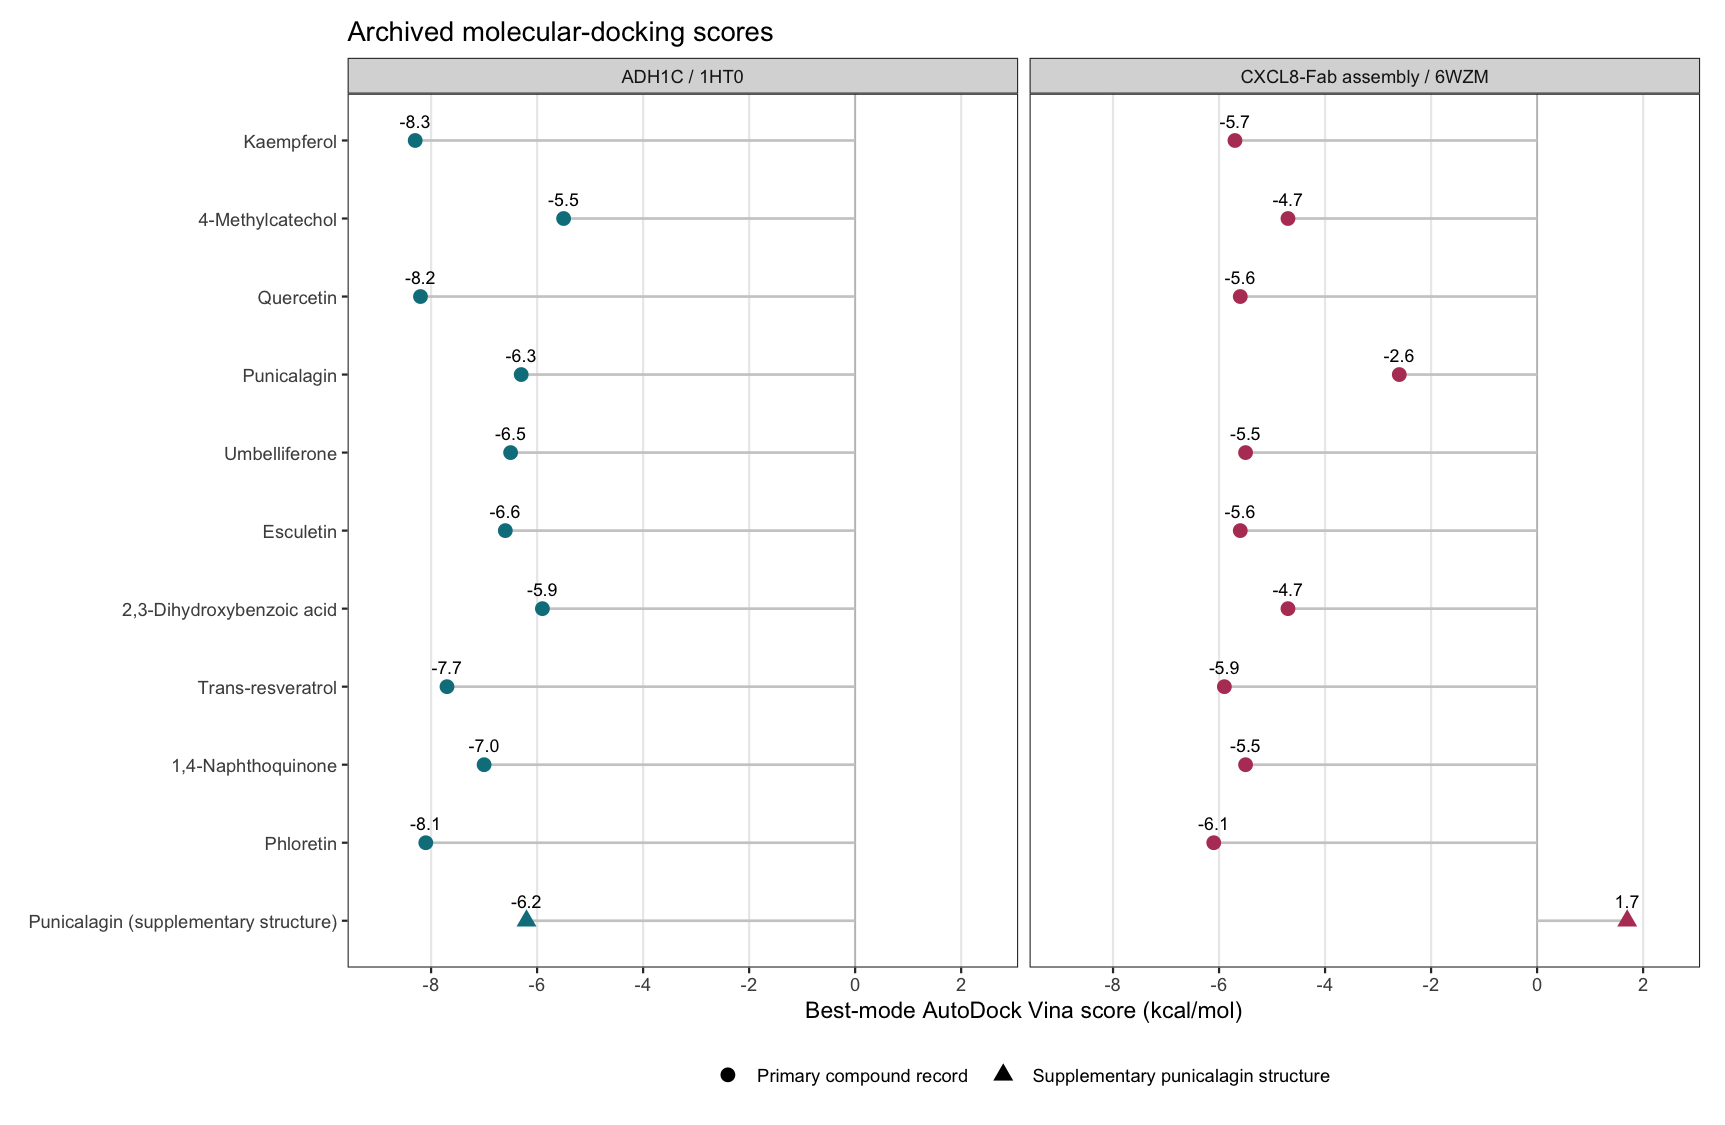

In [34]:
options(repr.plot.width = 11.5, repr.plot.height = 7.5)
records <- docking$scores
score_data <- rbind(
  data.frame(records, receptor = "ADH1C / 1HT0", score = records$ADH1C_1HT0),
  data.frame(records, receptor = "CXCL8-Fab assembly / 6WZM", score = records$CXCL8_Fab_6WZM)
)
score_data$compound <- factor(score_data$compound, levels = rev(records$compound))
score_data$receptor <- factor(score_data$receptor,
                               levels = c("ADH1C / 1HT0", "CXCL8-Fab assembly / 6WZM"))
score_plot <- ggplot(score_data, aes(score, compound)) +
  geom_vline(xintercept = 0, color = "grey75", linewidth = 0.4) +
  geom_segment(aes(x = 0, xend = score, yend = compound), color = "grey80", linewidth = 0.6) +
  geom_point(aes(color = receptor, shape = record_type), size = 3) +
  geom_text(aes(label = sprintf("%.1f", score)), nudge_y = 0.25, size = 3, show.legend = FALSE) +
  facet_grid(. ~ receptor) +
  scale_color_manual(values = c("#087F8C", "#B74065"), guide = "none") +
  scale_shape_manual(values = c(primary = 16, supplementary_structure = 17),
                      labels = c("Primary compound record", "Supplementary punicalagin structure"), name = NULL) +
  scale_x_continuous(limits = c(-9, 2.5), breaks = seq(-8, 2, 2)) +
  labs(title = "Archived molecular-docking scores",
       x = "Best-mode AutoDock Vina score (kcal/mol)", y = NULL) +
  theme_bw(base_size = 11) +
  theme(panel.grid.major.y = element_blank(), panel.grid.minor = element_blank(),
         legend.position = "bottom", plot.margin = margin(10, 12, 10, 10))
score_plot

### Why these two representative poses
I show phloretin-6WZM and kaempferol-1HT0 because each has the most favorable Vina score among the ten primary compounds in its receptor system. Kaempferol also ranks first in network proximity, connecting the leading network candidate with the strongest docking score for ADH1C. The four original panels below show the three-dimensional pose and two-dimensional contacts for each selected pair.

### Figure 9A: Phloretin in the 6WZM receptor system
I extract the four original PNG panels from my docking presentation and show each at its original resolution. These are the source images used in submitted Figure 9. In this first panel, phloretin lies within the predefined interface search region between CXCL8 chain F and Fab heavy chain C. It is the representative pose for the -6.1 kcal/mol result.

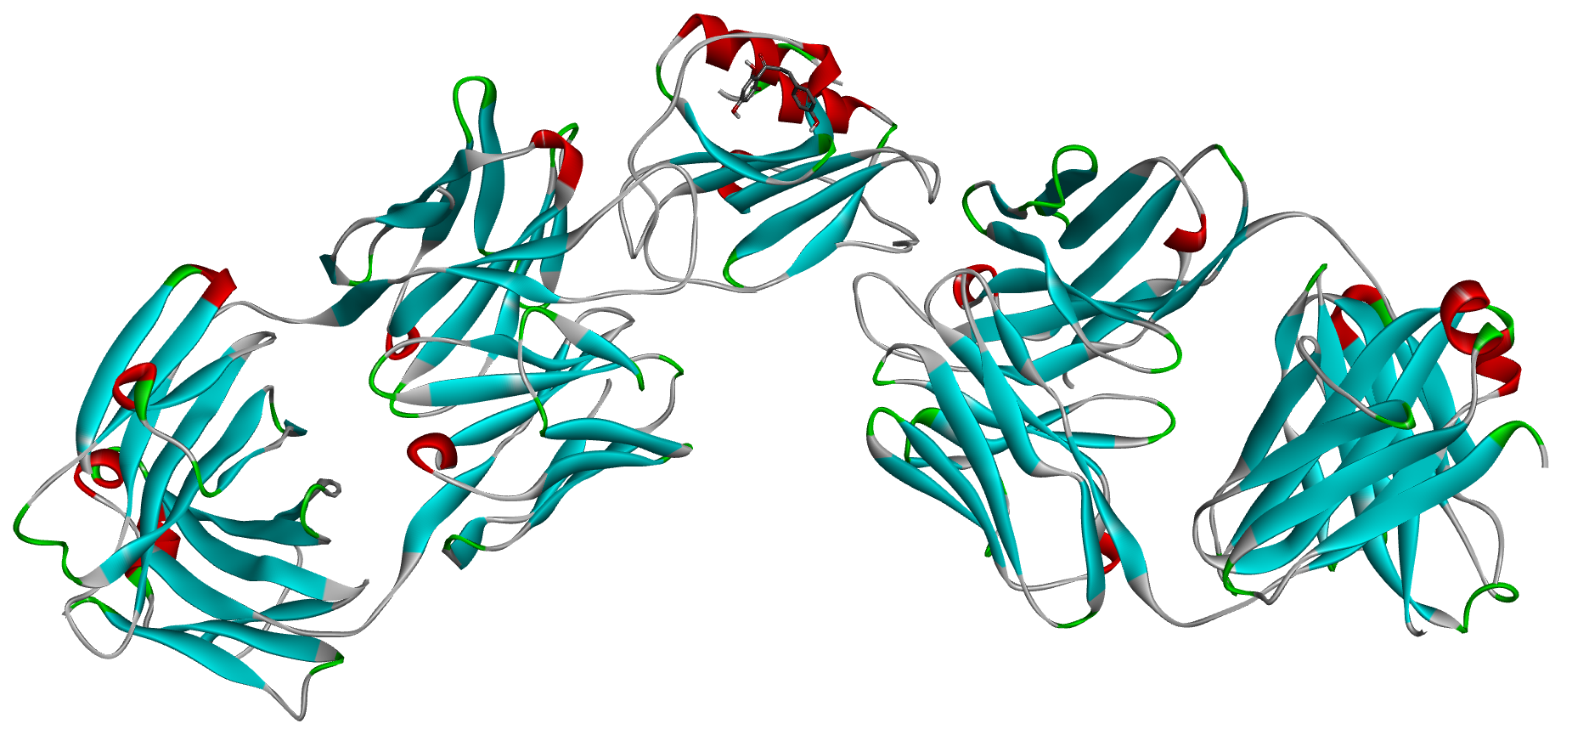

In [35]:
panel_log <- system2(python, "scripts/extract_docking_panels.py", stdout = TRUE, stderr = TRUE)
if (!is.null(attr(panel_log, "status"))) stop(paste(panel_log, collapse = "\n"))
IRdisplay::display_png(file = "figures/original/docking/phloretin_6wzm_3d.png")

### Figure 9B: Phloretin interaction map
The original interaction diagram identifies contacts on both sides of the interface. My manuscript describes a hydrogen bond with Tyr105 of Fab chain C, and contacts with Tyr13, Phe21 and Leu43 of CXCL8 chain F. The diagram also annotates an unfavorable donor-donor geometry involving Arg47. These annotations describe the geometry of the displayed pose.

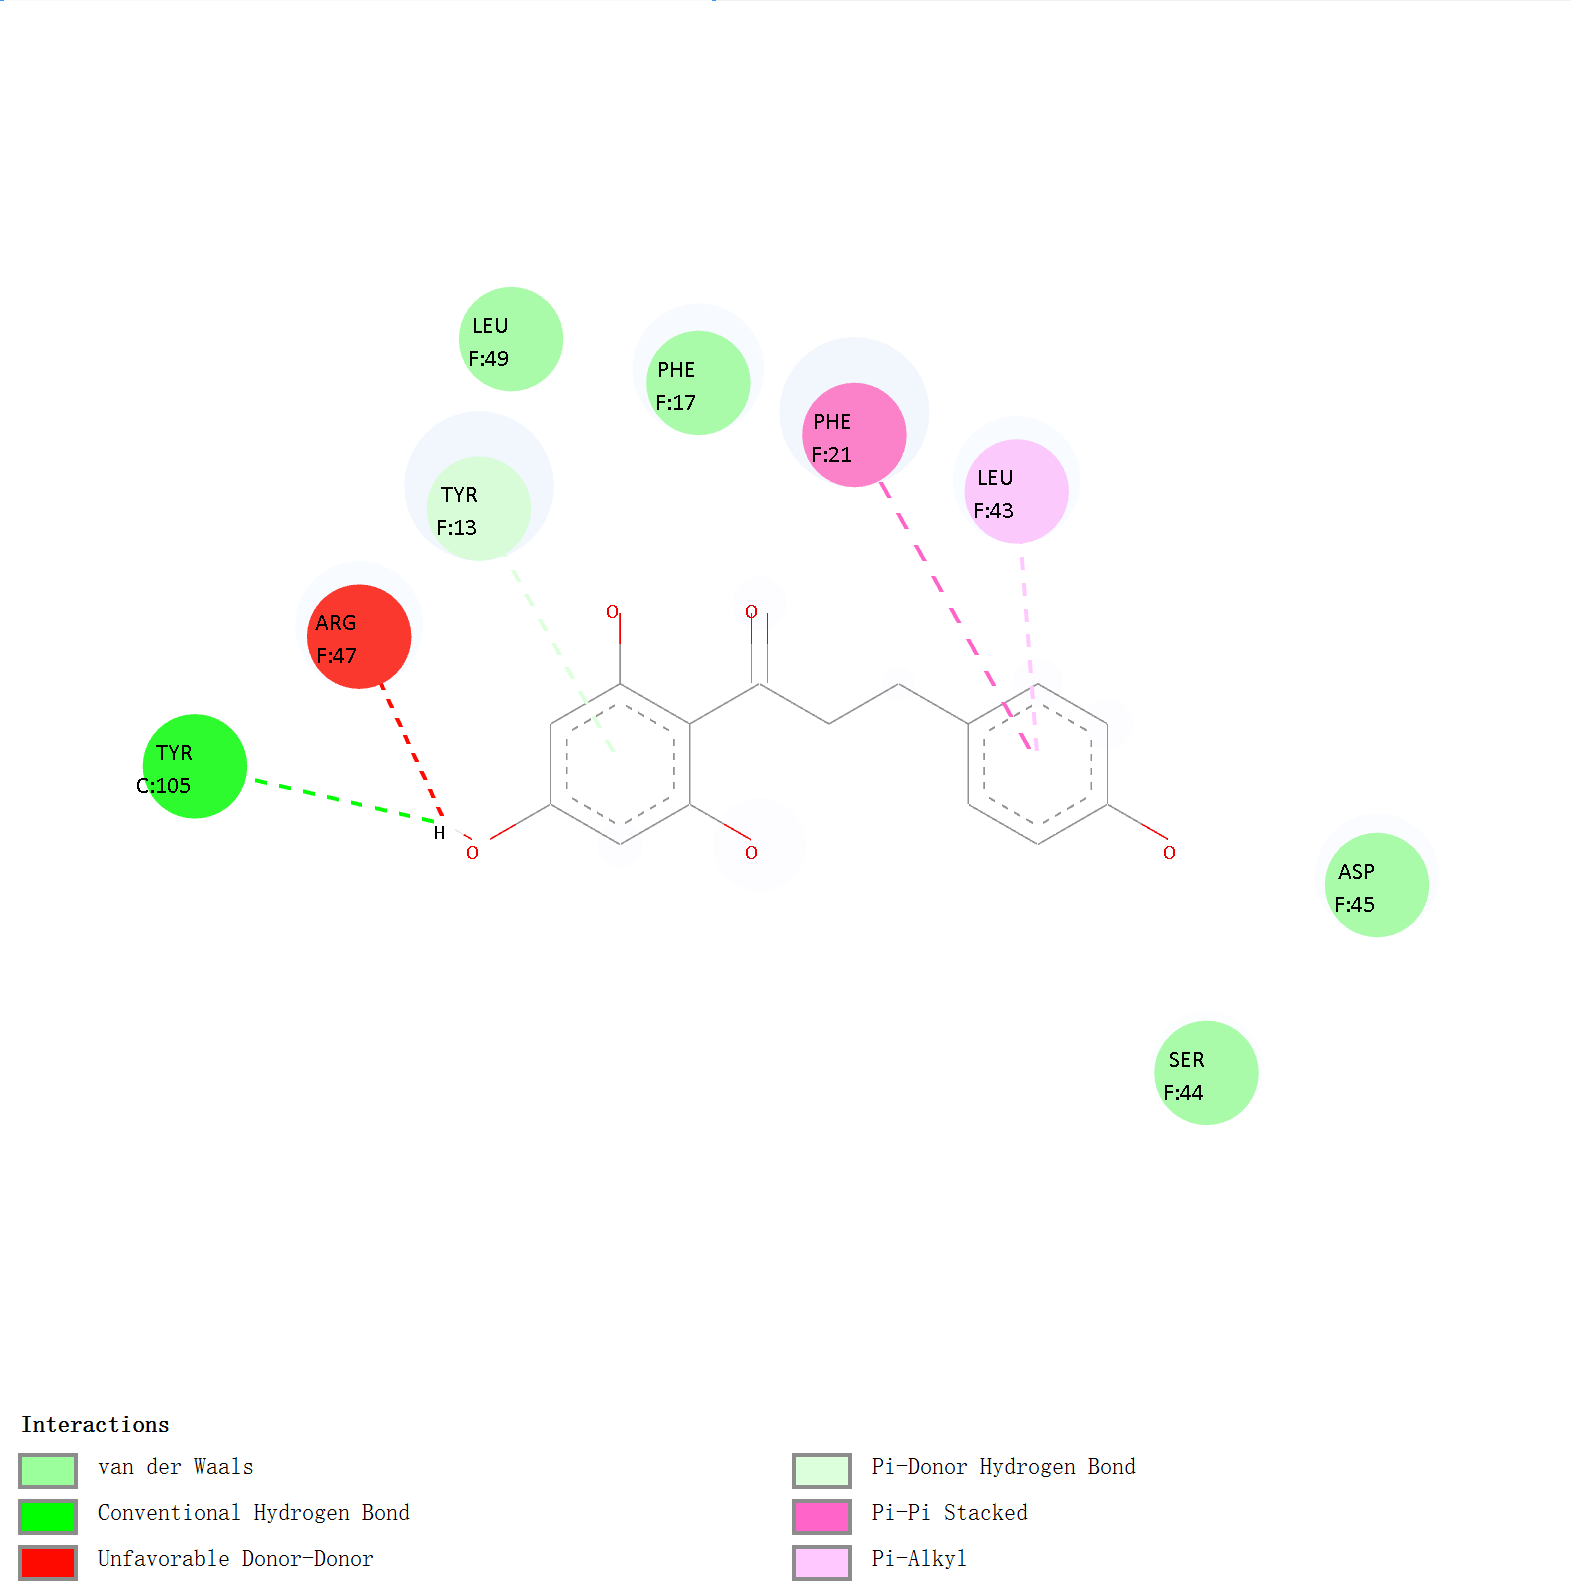

In [36]:
IRdisplay::display_png(file = "figures/original/docking/phloretin_6wzm_interactions.png")

### Figure 9C: Kaempferol in ADH1C
Kaempferol occupies the chain-A pocket in the prepared 1HT0 receptor, with a best-mode score of -8.3 kcal/mol. I selected this view because kaempferol led the ADH1C docking scores and the network-proximity ranking. The original three-dimensional panel places the ligand within the receptor used for that calculation.

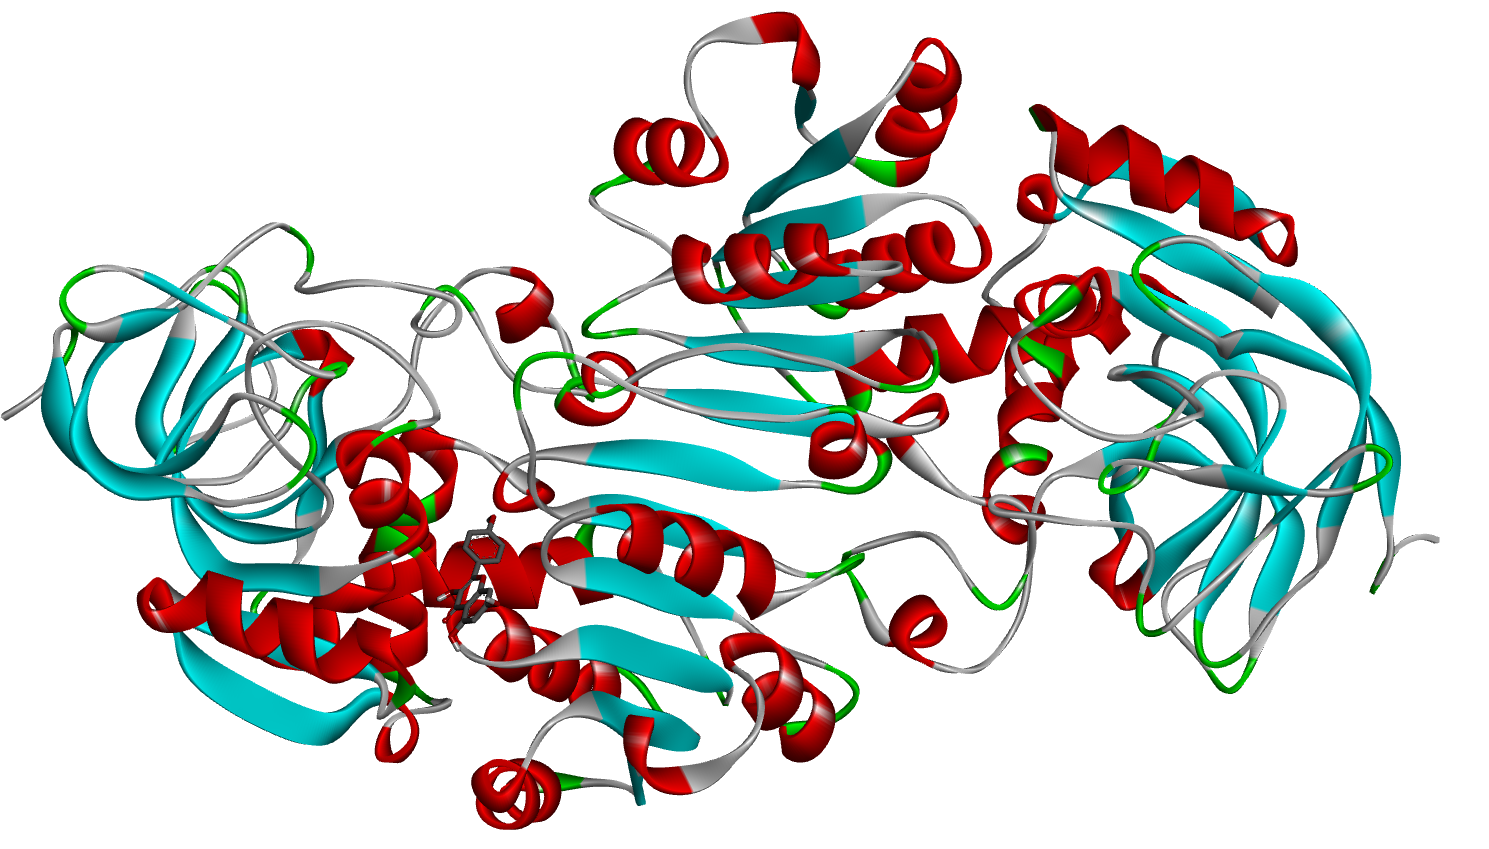

In [37]:
IRdisplay::display_png(file = "figures/original/docking/kaempferol_1ht0_3d.png")

### Figure 9D: Kaempferol interaction map
The original interaction map annotates a pi-cation contact with Arg47, a pi-sigma contact with Val203 and a carbon-hydrogen-bond contact with Gly201. Additional residues contribute van der Waals contacts, and Arg369 has an unfavorable donor-donor geometry. This gives a residue-level description of the representative pose reported in Section 3.5. The source PPT and four original PNG files are linked in the [docking record](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/docs/docking-provenance.md).

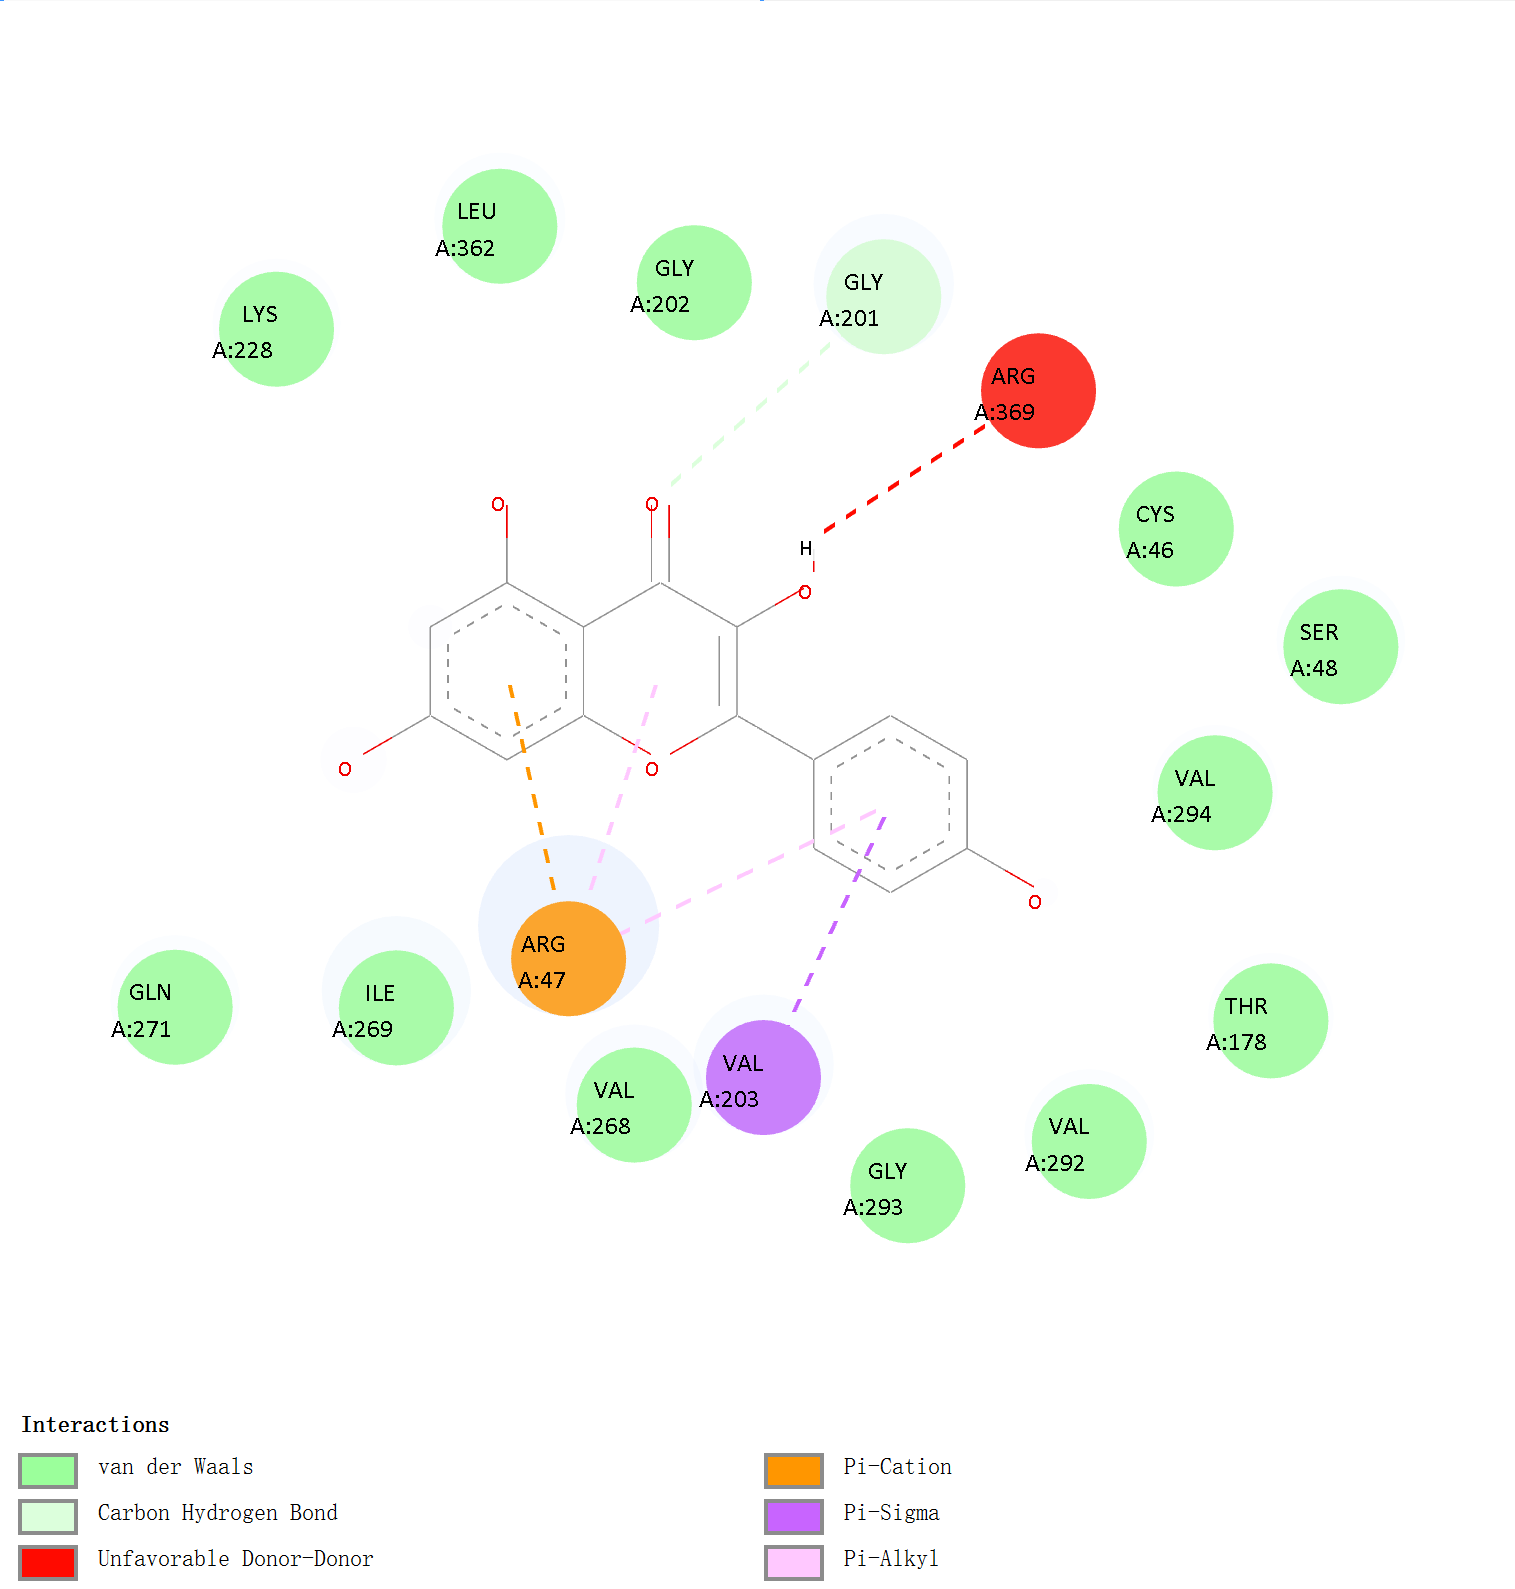

In [38]:
IRdisplay::display_png(file = "figures/original/docking/kaempferol_1ht0_interactions.png")

## What I take from these results
The expression analyses suggest that inflammatory recruitment and loss of mature epithelial functions are already established in adenomas. The carcinoma comparison adds matrix organization, adhesion and cell-cycle changes. The 29 genes that change in the same direction across both comparisons connect these tissue-stage findings to a focused protein network and a defined compound screen.

Kaempferol is the clearest candidate to carry forward from this analysis: it ranks first in network proximity and has the most favorable ADH1C docking score among the ten primary compounds. Phloretin provides the complementary structural example for the CXCL8-Fab system because it leads that receptor's scores. The next experimental question is whether these compounds engage the relevant targets and alter progression-associated expression or phenotypes in normal colon, adenoma and CRC models. I discuss this route from computational prioritization to target-engagement and organoid experiments in Section 4 of my manuscript.

<a id="checks-and-references"></a>
## Checks against the archived results
I compare the expression results with the archived differential-expression tables and check the identities of the 29 progression-associated genes. The existing analysis module also writes the complete result tables to `results/transcriptomics/`.

In [39]:
transcriptomics <- run_transcriptomics(root)
stopifnot(identical(de_summary, transcriptomics$summary),
          setequal(prog$gene, transcriptomics$progressive$gene))
show_table(read.csv("results/transcriptomics/verification.csv"), "Expression checks", digits = 15)
show_table(read.csv("results/enrichment/verification.csv"), "Enrichment table checks")

Transcriptomics complete: 725 / 312 / 1544 DEGs; 8 up + 21 down progression-associated genes.



check,passed,max_absolute_error
Adenoma_vs_Normal_saved_DEG_table,TRUE,5e-15
CRC_vs_Adenoma_saved_DEG_table,TRUE,5e-15
CRC_vs_Normal_saved_DEG_table,TRUE,5e-15
29_progressive_gene_identities,TRUE,0e+00


check,passed,expected_tested,expected_significant
Adenoma_vs_Normal__GO_BP,TRUE,4540,239
Adenoma_vs_Normal__GO_CC,TRUE,381,21
Adenoma_vs_Normal__GO_MF,TRUE,766,68
Adenoma_vs_Normal__KEGG_up,TRUE,211,10
Adenoma_vs_Normal__KEGG_down,TRUE,283,7
CRC_vs_Adenoma__GO_BP,TRUE,3394,93
CRC_vs_Adenoma__GO_CC,TRUE,322,19
CRC_vs_Adenoma__GO_MF,TRUE,563,13
CRC_vs_Adenoma__KEGG_up,TRUE,180,14
CRC_vs_Adenoma__KEGG_down,TRUE,168,1


I also check the SHA-256 hashes of the 196 preserved research inputs. This confirms that the input files still match the repository manifest.

In [40]:
input_checks <- system2(python, "scripts/verify_repository.py", stdout = TRUE, stderr = TRUE)
if (!is.null(attr(input_checks, "status"))) stop(paste(input_checks, collapse = "\n"))
cat(paste(input_checks, collapse = "\n"))

{
  "checked_input_files": 196,
  "checksum_failures": []
}

### Software used in this run
The R session below records the software used to execute these cells. Python package versions are recorded in `environment/requirements.txt` and `environment/requirements-notebook.txt`.

In [41]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: aarch64-apple-darwin20
Running under: macOS 27.0

Matrix products: default
BLAS:   /Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/lib/libRblas.0.dylib 
LAPACK: /Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.12.0

locale:
[1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8

time zone: Asia/Shanghai
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] patchwork_1.3.0 ggrepel_0.9.6   ggplot2_4.0.2   limma_3.62.2   

loaded via a namespace (and not attached):
 [1] rematch_2.0.0      gtable_0.3.6       jsonlite_2.0.0     dplyr_1.1.4       
 [5] compiler_4.4.3     crayon_1.5.3       tidyselect_1.2.1   Rcpp_1.0.14       
 [9] IRdisplay_1.1      textshaping_1.0.1  systemfonts_1.2.3  scales_1.4.0      
[13] readxl_1.4.5       uuid_1.2-1         fastmap_1.2.0      IRkernel_1.3.2    
[17] statmod_1.

## References and source records

- Expression data: [GEO GSE228012](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE228012), associated with [Lin et al.](https://doi.org/10.1002/advs.202410058).
- Compound-target records and network framework: [do Valle et al. (2021)](https://doi.org/10.1038/s43016-021-00243-7), [upstream code](https://github.com/italodovalle/polyphenols).
- Protein associations: [STRING](https://string-db.org/).
- Chemical identifiers and depictions: [PubChem](https://pubchem.ncbi.nlm.nih.gov/).
- Receptor structures: [PDB 1HT0](https://www.rcsb.org/structure/1HT0) and [PDB 6WZM](https://www.rcsb.org/structure/6WZM).

I assembled this notebook from my project files in November 2026, with Codex assistance for the executable presentation. The [provenance record](https://github.com/hiuuuuu33/colorectal-polyphenol-research/blob/main/docs/provenance.md) documents the original files, frozen enrichment results, historical randomization moments and submitted docking illustrations. A fresh seeded network randomization can be run with `scripts/python/network_analysis.py --mode randomize --n-random 1000`.